# TP 4: Assemble and train the full model

TP1 gave me a model that saw one character, TP2 added attention, and TP3 tested token transformations and residual connections. I now assemble these pieces and train them on Tiny Shakespeare.

My question is how I establish that the assembled model works, and what evidence justifies changing its design. I first test the mechanism, then follow optimisation and compare the existing training runs.


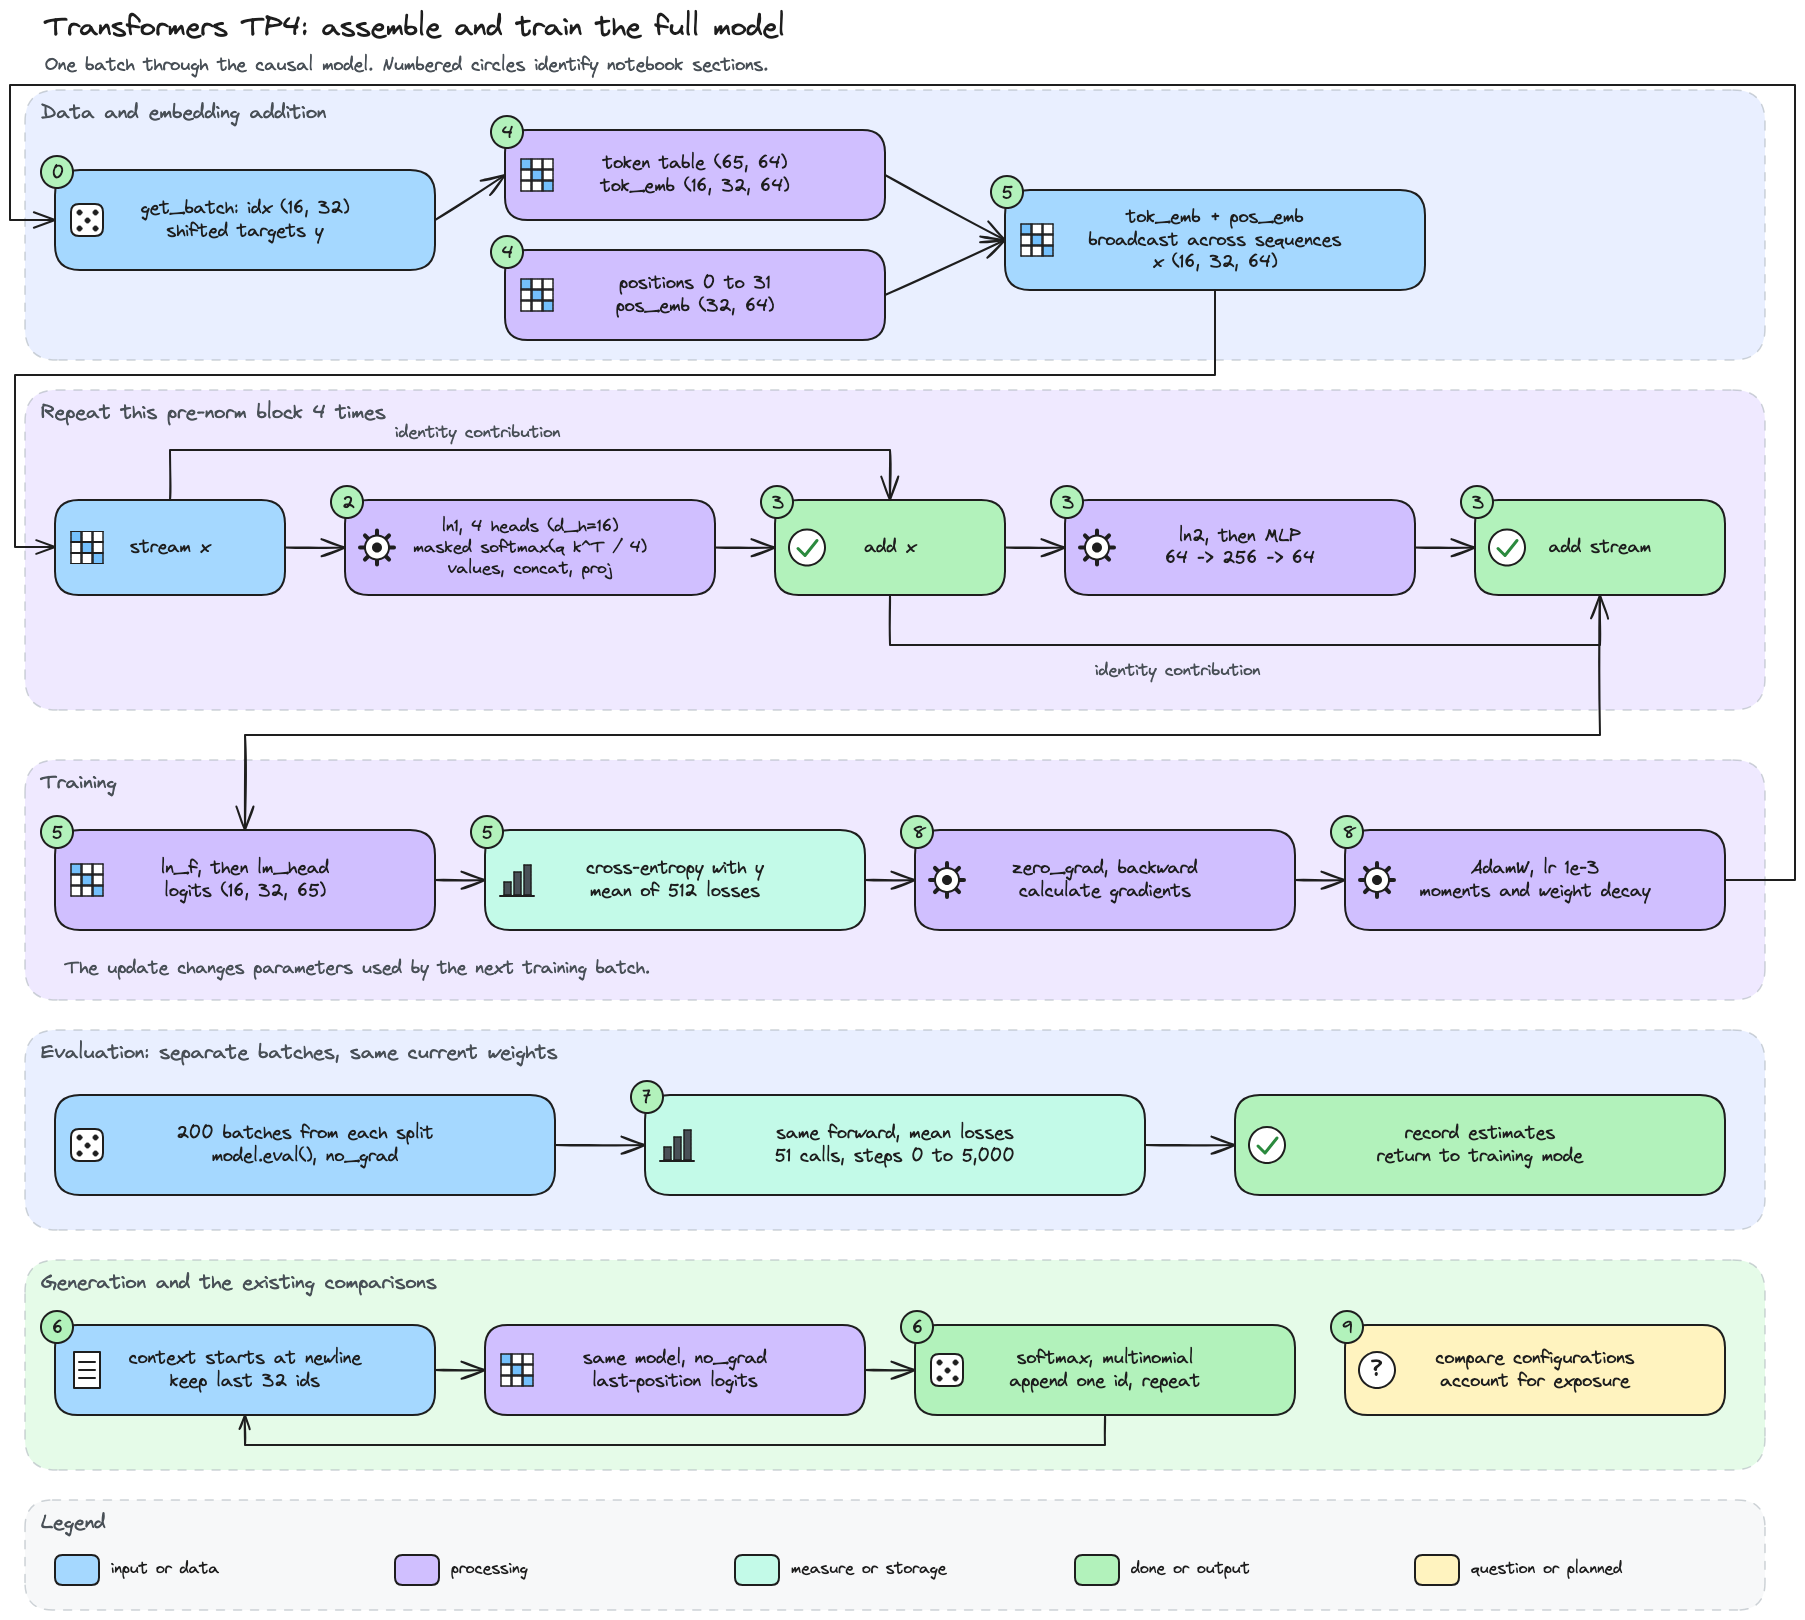

In [1]:
# Workflow diagram: one batch through the full model, with the training and generation loops.
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp4_workflow.png', width=900))

## 0. My problem, what I carry over, and the setup

In TP1, 2.45 nats was an empirical bigram reference fitted to pairs across the full Tiny Shakespeare corpus. The smoothed model fitted on training pairs scored 2.48 on validation, so neither number is a guaranteed lower bound.

I keep the data and split while allowing each prediction to use a longer prefix. The new model also has more parameters and a different training procedure, which limits what a lower loss can explain.


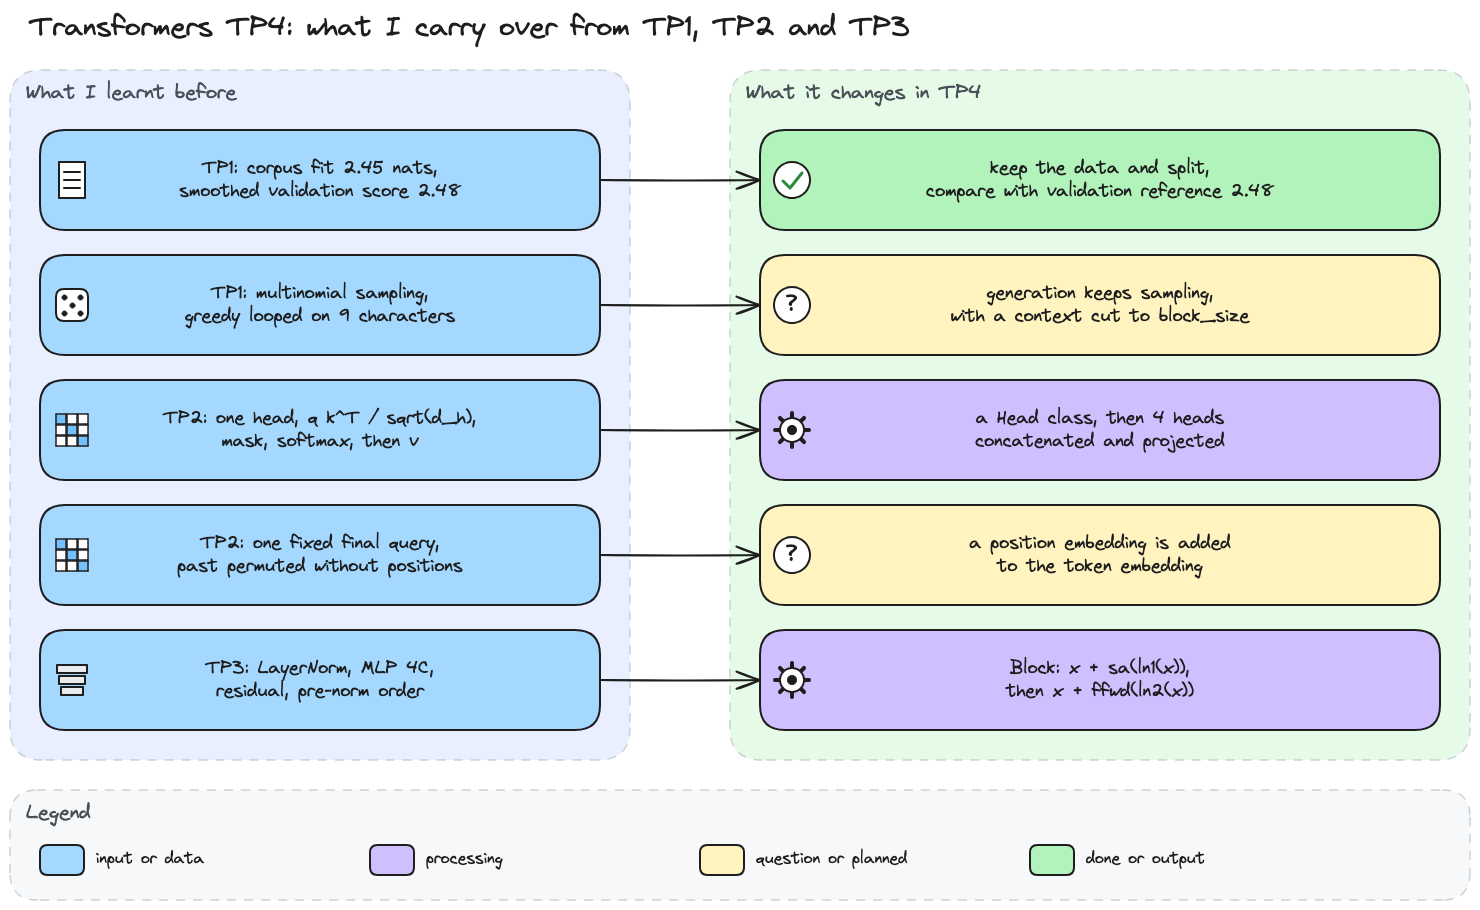

In [2]:
# What I carry over from TP1, TP2 and TP3 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp4_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - One head turns (16, 32, 64) into (16, 32, 16), and four heads concatenated give back (16, 32, 64). Sections 1 and 2 check the shapes.
> - Before training, the loss is close to ln(65) = 4.17, since the model favours no character yet. I measure it in section 5.
> - After 5,000 steps, the validation loss falls below the 2.45 nats of my TP1 bigram, because each prediction now sees up to 32 characters.
> - With dropout 0, the train and validation losses stay close, since the model is small next to the 1,003,854 training characters. Sections 8 and 9 follow both curves.
> - The samples gain the layout of the play, with names and line breaks, without correct English.
> - A longer context and more heads lower the validation loss. Section 9 tests block_size 16 and 64, then 1 head against 4.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in the earlier TPs.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I set seed 42 here, with explicit resets in later experiments. Reproducing a sequence also requires the same random calls, execution order and numerical environment.


In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the initial examples set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Seed: 42


I keep the existing constants so the classes and experiments share one configuration. The device line selects CUDA when available and the CPU otherwise. I check divisibility first because concatenation must recover the model's channel width.


In [4]:
# The constants of this setup, defined before any class that reads them.
batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

cpu


The device is `cpu` on my Mac, and the assert passes, so the 64 channels split evenly over the 4 heads. I then bring back my TP1 data cells without changing them.

In [5]:
# The TP1 data cells, kept as they are: download, vocabulary, encode and decode, 90/10 split.
from urllib.request import urlretrieve

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'text: {len(text):,} characters, vocab_size: {vocab_size}')
print(f'train_data: {len(train_data):,} ids, val_data: {len(val_data):,} ids')
print(decode(encode("hii there")))

text: 1,115,394 characters, vocab_size: 65
train_data: 1,003,854 ids, val_data: 111,540 ids
hii there


The text has 1,115,394 characters and 65 distinct ones. The 90/10 split gives 1,003,854 ids for training and 111,540 for validation, the same as in TP1, and `decode(encode(...))` gives `hii there` back.

In [6]:
# Mini-batches as in TP1: random windows of block_size from one split, sent to the device.
def get_batch(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """B random blocks of one split as inputs x and targets y shifted by one position."""
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size, (batch_size,)
    )
    x = torch.stack([
        source[i : i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in starts
    ])
    return x.to(device), y.to(device)


torch.manual_seed(1337)
xb, yb = get_batch("train")
print(f'xb {tuple(xb.shape)}, yb {tuple(yb.shape)}, device {xb.device}')
print(f'First window: {decode(xb[0].tolist())!r}')
print(f'Its targets:  {decode(yb[0].tolist())!r}')

xb (16, 32), yb (16, 32), device cpu
First window: "to corrupt a man's wife is\nwhen "
Its targets:  "o corrupt a man's wife is\nwhen s"


The batch contains 16 windows of 32 ids, with targets shifted by one character. In the first window, `to corrupt a man's wife is` starts the input. Each position contributes a prediction, even though neighbouring positions share much of their context.

Before building the model, I count both training and evaluation batches. This separates the optimisation budget from the work needed to measure it.


d_h = n_embd / n_head = 64 / 4 = 16
Tokens per batch: 16 x 32 = 512 inputs, and as many targets
Training: 5,000 batches, each with a backward pass
Evaluation: 51 x 2 x 200 = 20,400 batches, forward only
Sampled target positions in training: 2,560,000, 2.55 times the split length in count


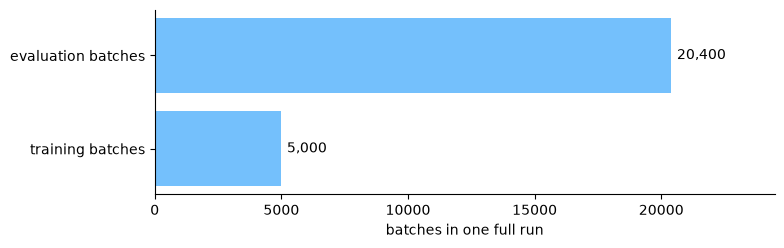

In [7]:
# The questions of the setup: head size, tokens per batch, and the work of a full run.
import matplotlib.pyplot as plt

d_h = n_embd // n_head
tokens_per_batch = batch_size * block_size
evaluations = len(range(0, max_iters, eval_interval)) + 1  # includes zero and the final step
eval_batches = evaluations * 2 * eval_iters  # train and val, eval_iters batches each
print(f'd_h = n_embd / n_head = {n_embd} / {n_head} = {d_h}')
print(f'Tokens per batch: {batch_size} x {block_size} = {tokens_per_batch:,} inputs, '
      f'and as many targets')
print(f'Training: {max_iters:,} batches, each with a backward pass')
print(f'Evaluation: {evaluations} x 2 x {eval_iters} = {eval_batches:,} batches, forward only')
print(f'Sampled target positions in training: {max_iters * tokens_per_batch:,}, '
      f'{max_iters * tokens_per_batch / len(train_data):.2f} times the split length in count')

fig, ax = plt.subplots(figsize=(8, 2.4))
work = {'training batches': max_iters, 'evaluation batches': eval_batches}
bars = ax.barh(list(work), list(work.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:,}' for value in work.values()], padding=4)
ax.set_xlim(0, max(work.values()) * 1.2)
ax.set_xlabel('batches in one full run')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Each head has 64 / 4 = 16 channels, and one batch contributes 16 × 32 = 512 target positions. The full run processes 2,560,000 positions, equivalent in count to 2.55 times the training split. Random windows can overlap and repeat, so this does not mean complete epochs or unique coverage.

The loop evaluates before training at step 0 and after every 100 steps through step 5,000. That gives 51 calls and 20,400 evaluation batches, because each call measures 200 batches from each split.


> *My conclusion:*
>
> I retain the TP1 data and split, then account for the work before training. Sampled target positions measure the processing budget, while shared contexts prevent treating every position as an independent observation.
>
> My answers to the three questions of the preparation step:
>
> 1. Each head has d_h = 64 / 4 = 16 channels.
> 2. Each batch holds 512 inputs and 512 targets.
> 3. Reducing max_iters reduces training and evaluation calls. Reducing eval_iters reduces the work per evaluation, which currently totals 20,400 batches.


## 1. Code one head

I turn the TP2 operations into a reusable class. My uncertainty is whether packaging them with a stored mask and dropout preserves the same causal calculation. I check shapes first, then numerical agreement and a changed future token.


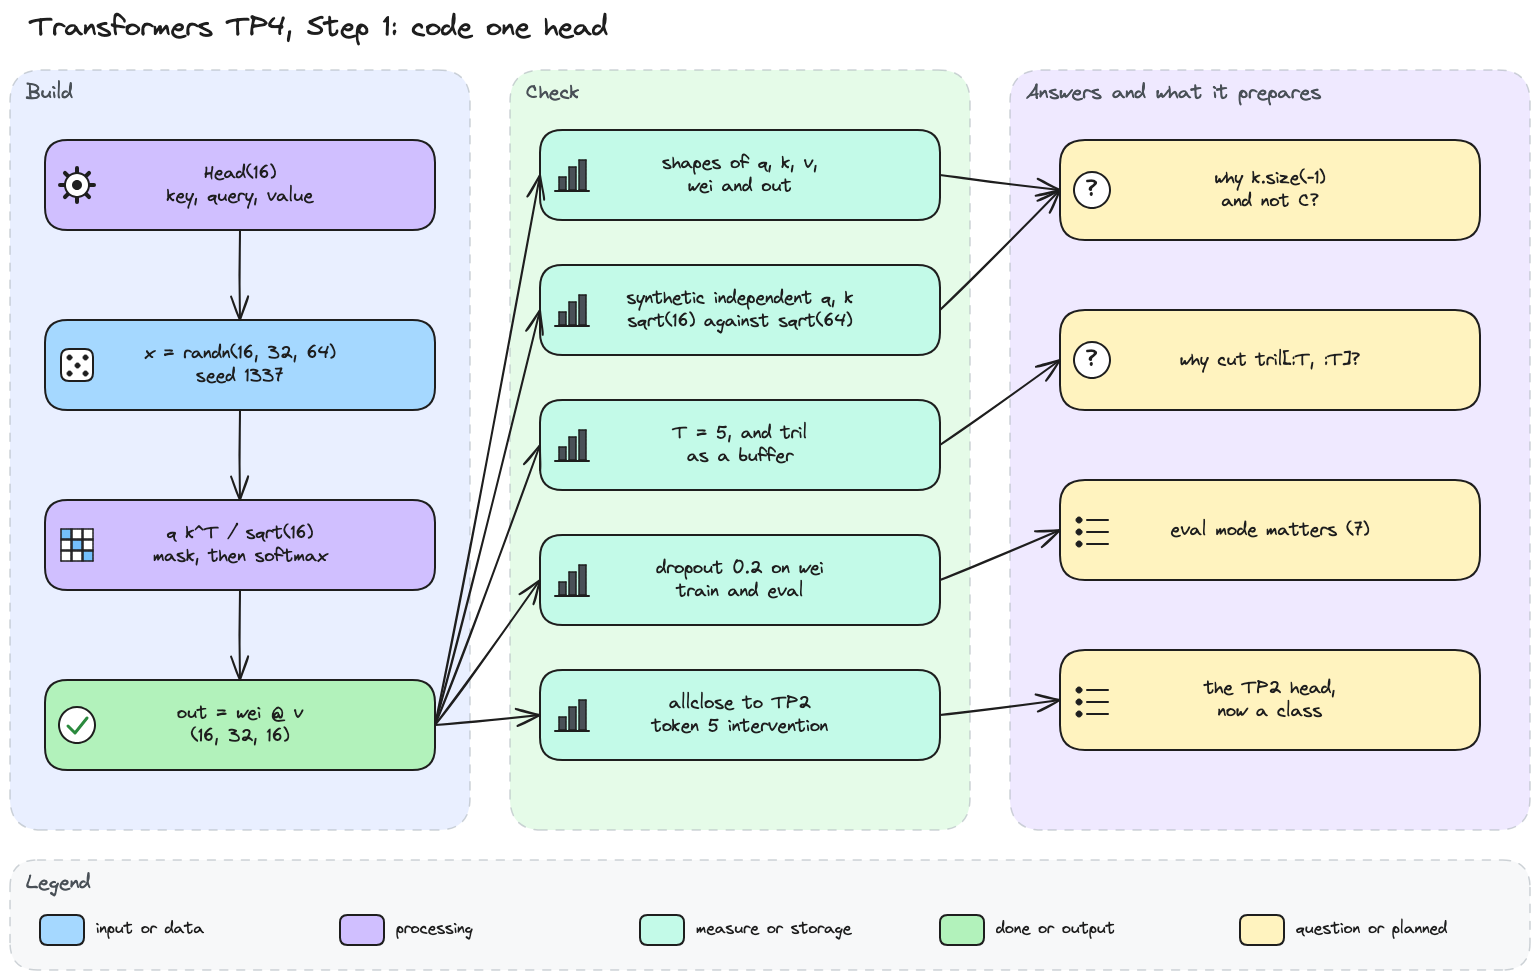

In [8]:
# Step 1 diagram: one head as a class, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step1.png', width=900))

In [9]:
# One attention head as a class: the operations I validated in TP2, with dropout on the weights.
import torch.nn as nn
import torch.nn.functional as F


class Head(nn.Module):
    """One head of causal self-attention, of size head_size."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

The scale uses `k.size(-1)**-0.5`, the mask uses `self.tril[:T, :T]`, and the output is `wei @ v`. Shapes tell me whether these operations connect correctly. They cannot reveal every wrong axis or an accidental view of a future token.


In [10]:
# Do the shapes match the existing? One head of size 16 on x of shape (16, 32, 64).
torch.manual_seed(1337)
head = Head(16)
x = torch.randn(batch_size, block_size, n_embd)
k, q, v = head.key(x), head.query(x), head.value(x)
wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5
wei = F.softmax(wei.masked_fill(head.tril == 0, float('-inf')), dim=-1)
out = head(x)
for name, tensor in (('x', x), ('q', q), ('k', k), ('v', v), ('wei', wei), ('out', out)):
    print(f'{name}: {tuple(tensor.shape)}')

x: (16, 32, 64)
q: (16, 32, 16)
k: (16, 32, 16)
v: (16, 32, 16)
wei: (16, 32, 32)
out: (16, 32, 16)


The head maps (16, 32, 64) to (16, 32, 16), as expected. Queries, keys and values have 16 channels, while each attention row has 32 possible positions.

To isolate the scaling denominator, I reuse the same synthetic scores for both divisions. These independent standard-normal queries and keys give a controlled reference separate from the head's projected tensors.


head of 16, divided by sqrt(k.size(-1) = 16): variance 0.99, mean last-row entropy 2.98
head of 16, divided by sqrt(C = 64): variance 0.25, mean last-row entropy 3.34
head of 64, divided by sqrt(k.size(-1) = 64): variance 1.00, mean last-row entropy 3.03
head of 64, divided by sqrt(C = 64): variance 1.00, mean last-row entropy 3.03
Entropy of a uniform last row over 32 tokens: 3.47


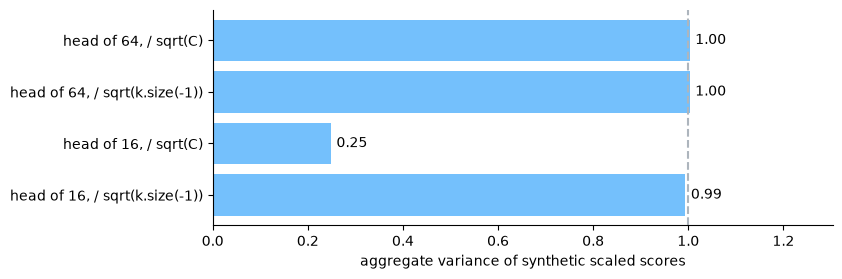

In [11]:
# Why k.size(-1) and not C? Unit-variance q and k, for 4 heads of 16 and for 1 head of 64.
import math

torch.manual_seed(1337)
variances = {}
for head_size in (n_embd // n_head, n_embd):
    q_unit = torch.randn(batch_size, block_size, head_size)
    k_unit = torch.randn(batch_size, block_size, head_size)
    raw = q_unit @ k_unit.transpose(-2, -1)  # each score sums head_size products
    for name, scale in (('k.size(-1)', k_unit.size(-1)), ('C', n_embd)):
        scores = raw * scale**-0.5
        last = F.softmax(scores.masked_fill(head.tril == 0, float('-inf')), dim=-1)[:, -1]
        entropy = -(last * torch.log(last.clamp_min(1e-12))).sum(dim=-1).mean()
        variances[f'head of {head_size}, / sqrt({name})'] = scores.var().item()
        print(f'head of {head_size}, divided by sqrt({name} = {scale}): '
              f'variance {scores.var():.2f}, mean last-row entropy {entropy:.2f}')
print(f'Entropy of a uniform last row over {block_size} tokens: {math.log(block_size):.2f}')

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(list(variances), list(variances.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.2f}' for value in variances.values()], padding=4)
ax.axvline(1, linestyle='--', color='#adb5bd')
ax.set_xlim(0, max(variances.values()) * 1.3)
ax.set_xlabel('aggregate variance of synthetic scaled scores')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For independent, zero-mean, unit-variance components and independent queries and keys, the variance of a dot product grows with head size. Dividing by its square root gives theoretical variance one under those assumptions. Projected or trained queries and keys need not satisfy them.

For head size 16, the measured variance is 0.99 with √16 and 0.25 with √64. The average last-row entropy is 2.98 and 3.34 respectively, compared with 3.47 for uniform weights. Reusing queries and keys across entries makes those score entries dependent.

For head size 64, the denominators coincide and both measured variances round to 1.00. This checks the intended scale in the synthetic example without guaranteeing the same statistics during training. I next shorten the input while keeping the head unchanged to test the mask slice.


In [12]:
# Why cut tril[:T, :T]? A context of 5 tokens, with the cut and with the full 32 x 32 mask.
short = x[:, :5]
print(f'Head on a context of 5 tokens: {tuple(head(short).shape)}')
scores = head.query(short) @ head.key(short).transpose(-2, -1)
try:
    scores.masked_fill(head.tril == 0, float('-inf'))
except RuntimeError as error:
    print(f'With the full mask: {error}')

print(f'Parameters: {sum(p.numel() for p in head.parameters()):,}, buffers: '
      f'{[(name, tuple(b.shape)) for name, b in head.named_buffers()]}')
print(f'tril in the state_dict: {"tril" in head.state_dict()}, '
      f'tril learned: {head.tril.requires_grad}')

Head on a context of 5 tokens: (16, 5, 16)
With the full mask: The size of tensor a (32) must match the size of tensor b (5) at non-singleton dimension 2
Parameters: 3,072, buffers: [('tril', (32, 32))]
tril in the state_dict: True, tril learned: False


The unchanged head accepts five tokens with a 5 × 5 mask, while the full 32 × 32 mask causes a shape error. This matters because generation starts with a shorter context. The mask is a stored buffer, outside the 3,072 trainable parameters.

I next keep the head's weights and input fixed on a copy and change only dropout and its mode. That isolates what dropout does to already computed attention weights.


train mode: row sums from 0.000 to 1.250, visible weights set to 0: 19.67%
eval mode: row sums from 1.000 to 1.000, visible weights set to 0: 0.00%
TP4 value dropout = 0.0: weights unchanged in train mode True


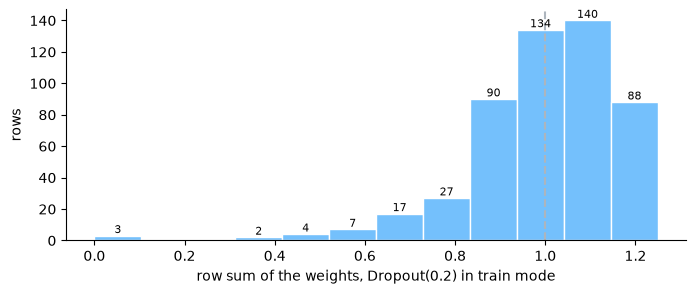

In [13]:
# What would dropout do to the weights? A copy of the head with Dropout(0.2), train then eval.
import copy

noisy = copy.deepcopy(head)
noisy.dropout = nn.Dropout(0.2)
k_noisy = noisy.key(x)
scores = noisy.query(x) @ k_noisy.transpose(-2, -1) * k_noisy.size(-1)**-0.5
clean = F.softmax(scores.masked_fill(noisy.tril == 0, float('-inf')), dim=-1).detach()
visible = noisy.tril.bool().expand_as(clean)  # the weights on past and current tokens
row_sums = {}
for mode in ('train', 'eval'):
    noisy.train(mode == 'train')
    dropped = noisy.dropout(clean)
    row_sums[mode] = dropped.sum(dim=-1).flatten()
    print(f'{mode} mode: row sums from {row_sums[mode].min():.3f} to {row_sums[mode].max():.3f}, '
          f'visible weights set to 0: {100 * (dropped[visible] == 0).float().mean():.2f}%')
print(f'TP4 value dropout = {dropout}: weights unchanged in train mode '
      f'{torch.equal(head.dropout(clean), clean)}')

fig, ax = plt.subplots(figsize=(8, 3))
counts, _, bars = ax.hist(row_sums['train'], bins=12, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=8)
ax.axvline(1, linestyle='--', color='#adb5bd')
ax.set_xlabel('row sum of the weights, Dropout(0.2) in train mode')
ax.set_ylabel('rows')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With dropout 0.2 in training mode, 19.67% of visible weights become zero in this draw. The remaining weights are multiplied by 1 / 0.8 = 1.25, preserving each weight in expectation. Individual row sums range from 0.000 to 1.250, so these rows are no longer probability distributions.

Evaluation mode restores row sums of 1.000, and the current dropout of 0.0 changes no weights. I now compare the class with the TP2 calculation using the same layers and input. Replacing a later token then checks causality, which matching shapes and row sums cannot establish.


In [14]:
# Is this my TP2 head? The TP2 lines with the same layers, then token 5 replaced.
tril = torch.tril(torch.ones(block_size, block_size))
wei_tp2 = q @ k.transpose(-2, -1) * k.size(-1)**-0.5  # TP2 section 5, line by line
wei_tp2 = wei_tp2.masked_fill(tril == 0, float('-inf'))
wei_tp2 = F.softmax(wei_tp2, dim=-1)
print(f'Class against the TP2 lines: allclose {torch.allclose(head(x), wei_tp2 @ v)}')

changed = x.clone()
changed[0, 5] = torch.randn(n_embd)
moves = (head(changed) - head(x))[0].abs().max(dim=-1).values.detach()
print(f'Token 5 replaced, largest change of rows 0 to 7: '
      f'{[round(m, 2) for m in moves[:8].tolist()]}')
print(f'Rows 0 to 4 unchanged: {torch.equal(head(changed)[0, :5], head(x)[0, :5])}')

Class against the TP2 lines: allclose True
Token 5 replaced, largest change of rows 0 to 7: [0.0, 0.0, 0.0, 0.0, 0.0, 0.26, 0.14, 0.12]
Rows 0 to 4 unchanged: True


The class and the TP2 calculation pass `allclose` with shared weights and inputs. This check allows both absolute and relative error, so agreement on this example does not exclude every possible implementation bug.

The absolute tolerance matters near zero, while the relative tolerance scales with the reference value.

Replacing token 5 changes rows 5, 6 and 7 by 0.26, 0.14 and 0.12, while rows 0 to 4 remain unchanged. The intervention checks the expected direction of influence. The triangular mask supplies the causal restriction in the implementation.


> *My conclusion:*
>
> The head passes the shape, shared-weight and future-token checks. My expected output shape holds, and I can now test whether several heads combine without mixing sequences or positions.
>
> My answers to the two questions of this step:
>
> 1. The scale uses k.size(-1) because each score sums that many products. Under the synthetic independence and variance assumptions, √16 gives the intended variance near one.
> 2. I slice the mask to T because a context can be shorter than block_size. The five-token example works with the slice and fails with the full mask.


## 2. Combine several heads

I want several trainable ways to weight the same visible tokens. I concatenate the heads along their channels, then apply a projection that can combine them. I check the channel slices before interpreting any difference between heads.


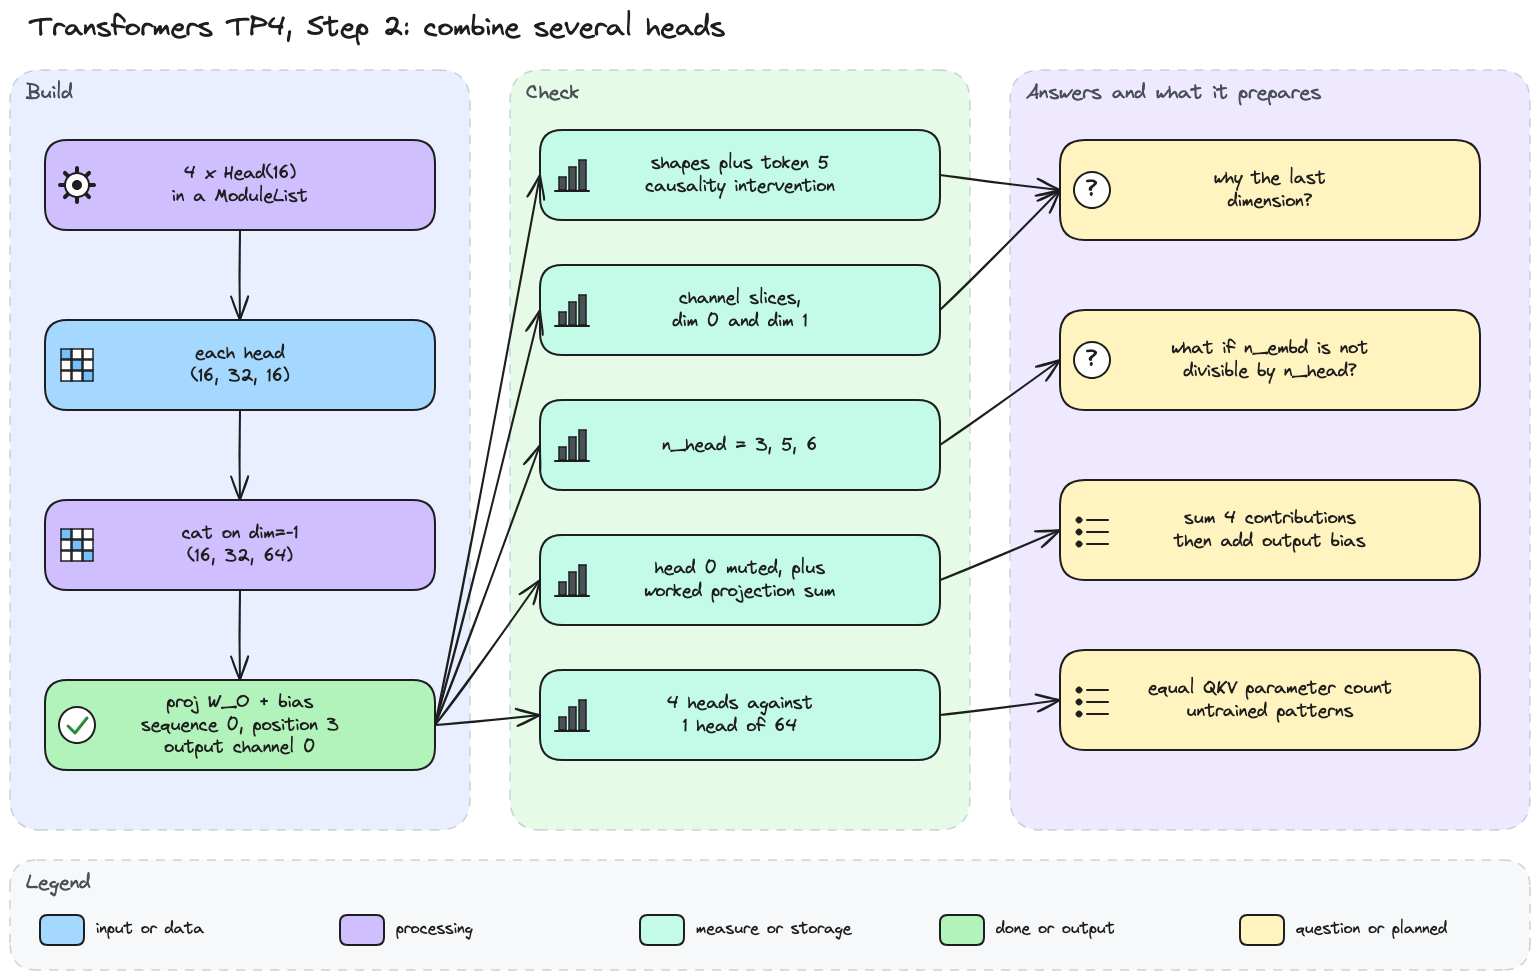

In [15]:
# Step 2 diagram: four heads concatenated then projected, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step2.png', width=900))

In [16]:
# Several heads in parallel: concatenate their outputs, then mix them with a projection.
class MultiHeadAttention(nn.Module):
    """num_heads heads of size head_size, concatenated and projected back to n_embd."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1
        )
        return self.dropout(self.proj(out))

I use `dim=-1` so every head describes the same sequence and position side by side. With head_size = n_embd // n_head, their combined width must match the input of `proj`. The shape and future-token checks test these two requirements separately.


In [17]:
# Do four heads give back 64 channels? Shapes of each head, the concatenation and the output.
torch.manual_seed(1337)
head_size = n_embd // n_head
sa = MultiHeadAttention(n_head, head_size)
x = torch.randn(batch_size, block_size, n_embd)
head_outs = [h(x) for h in sa.heads]
concat = torch.cat(head_outs, dim=-1)
out = sa(x)
print(f'Each head: {[tuple(o.shape) for o in head_outs]}')
print(f'Concatenation: {tuple(concat.shape)}, after proj: {tuple(out.shape)}')
print(f'Parameters: heads {sum(p.numel() for p in sa.heads.parameters()):,}, '
      f'proj {sum(p.numel() for p in sa.proj.parameters()):,}, '
      f'total {sum(p.numel() for p in sa.parameters()):,}')

changed = x.clone()
changed[0, 5] = torch.randn(n_embd)
print(f'Token 5 replaced, rows 0 to 4 unchanged: {torch.equal(sa(changed)[0, :5], out[0, :5])}')

Each head: [(16, 32, 16), (16, 32, 16), (16, 32, 16), (16, 32, 16)]
Concatenation: (16, 32, 64), after proj: (16, 32, 64)
Parameters: heads 12,288, proj 4,160, total 16,448
Token 5 replaced, rows 0 to 4 unchanged: True


Four outputs of (16, 32, 16) combine into (16, 32, 64), and the projection preserves that shape. This confirms my shape hypothesis on the example, with 16,448 parameters in the module. Changing token 5 again leaves rows 0 to 4 unchanged.

I next inspect each channel slice and deliberately concatenate along the other axes. These failures help explain why a plausible tensor shape alone is not enough.


In [18]:
# Why the last dimension? Each slice of 16 channels, then the concatenation on dim 0 and dim 1.
for h, head_out in enumerate(head_outs):
    piece = concat[..., head_size * h:head_size * (h + 1)]
    print(f'channels {head_size * h} to {head_size * (h + 1) - 1} are head {h}: '
          f'{torch.equal(piece, head_out)}')
for dim in (0, 1):
    wrong = torch.cat(head_outs, dim=dim)
    try:
        sa.proj(wrong)
    except RuntimeError as error:
        print(f'cat on dim={dim}: {tuple(wrong.shape)}, proj fails: {error}')

channels 0 to 15 are head 0: True
channels 16 to 31 are head 1: True
channels 32 to 47 are head 2: True
channels 48 to 63 are head 3: True
cat on dim=0: (64, 32, 16), proj fails: mat1 and mat2 shapes cannot be multiplied (2048x16 and 64x64)
cat on dim=1: (16, 128, 16), proj fails: mat1 and mat2 shapes cannot be multiplied (2048x16 and 64x64)


Each block of 16 channels of the concatenation is exactly one head, from channels 0 to 15 for head 0 up to 48 to 63 for head 3. Concatenating on dim 0 gives (64, 32, 16), as if there were 64 sequences, and on dim 1 gives (16, 128, 16), as if each sequence had 128 positions. In both cases `proj` fails, since it expects 64 channels per token.

The last dimension is the only one where the four heads describe the same token side by side.

In [19]:
# What if n_embd is not divisible by n_head? Three head counts that do not divide 64.
for count in (3, 5, 6):
    size = n_embd // count
    trial = MultiHeadAttention(count, size)
    try:
        trial(x)
    except RuntimeError as error:
        print(f'n_head = {count}: head_size {size}, {count * size} channels after cat, '
              f'{n_embd} % {count} = {n_embd % count}, proj fails: {error}')

n_head = 3: head_size 21, 63 channels after cat, 64 % 3 = 1, proj fails: mat1 and mat2 shapes cannot be multiplied (512x63 and 64x64)
n_head = 5: head_size 12, 60 channels after cat, 64 % 5 = 4, proj fails: mat1 and mat2 shapes cannot be multiplied (512x60 and 64x64)
n_head = 6: head_size 10, 60 channels after cat, 64 % 6 = 4, proj fails: mat1 and mat2 shapes cannot be multiplied (512x60 and 64x64)


With 3, 5 or 6 heads, integer division leaves only 63, 60 or 60 concatenated channels. The projection expects 64, so all three configurations fail. The initial divisibility assertion catches this constraint earlier.

To locate where heads interact, I set one existing head's output to zero while keeping the other outputs and projection fixed. This tests the projection's mixing, without claiming that the muted head is more important.


Channels changed in the concatenation: 16 of 64
Channels changed after proj: 64 of 64


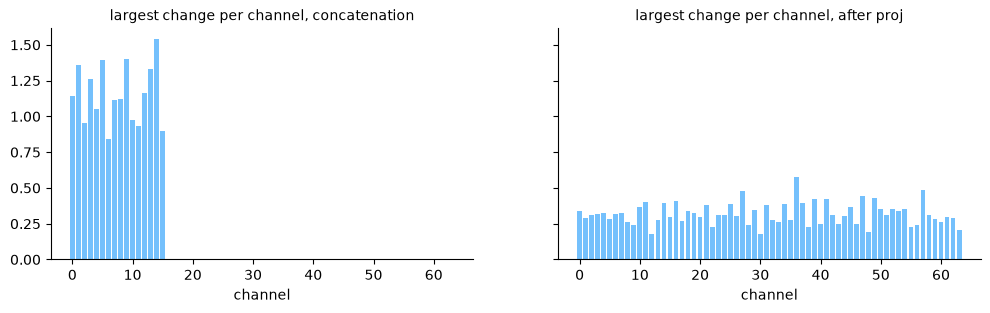

In [20]:
# Where do the heads meet? Head 0 set to zero, before and after the projection.
muted = concat.clone()
muted[..., :head_size] = 0
before = (muted - concat).abs().amax(dim=(0, 1)).detach()
after = (sa.proj(muted) - sa.proj(concat)).abs().amax(dim=(0, 1)).detach()
print(f'Channels changed in the concatenation: {(before > 0).sum().item()} of {n_embd}')
print(f'Channels changed after proj: {(after > 0).sum().item()} of {n_embd}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, change, title in ((axes[0], before, 'concatenation'), (axes[1], after, 'after proj')):
    ax.bar(range(n_embd), change, color='#74c0fc')
    ax.set_xlabel('channel')
    ax.set_title(f'largest change per channel, {title}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

Muting head 0 changes its 16 channels before projection and all 64 channels afterward. The projection combines contributions from different head slices into each output channel.

I can make this concrete by expanding one output into the four weighted contributions and its bias. I keep the existing tensors so the arithmetic describes exactly the same prediction.


In [21]:
# Expand one projected output into its four head contributions and bias.
demo_head_values = concat[0, 3].detach().reshape(n_head, head_size)
demo_proj_row = sa.proj.weight[0].detach().reshape(n_head, head_size)
demo_contributions = (demo_head_values * demo_proj_row).sum(dim=-1)
demo_proj_bias = sa.proj.bias[0].detach()
demo_projected = demo_contributions.sum() + demo_proj_bias
assert dropout == 0.0
assert torch.allclose(demo_projected, out[0, 3, 0].detach(), atol=1e-7, rtol=1e-5)
print('Sequence 0, position 3, output channel 0')
print(f'Four head contributions: {[round(v, 6) for v in demo_contributions.tolist()]}')
print(f'Sum {demo_contributions.sum():.6f} + bias {demo_proj_bias:.6f} '
      f'= {demo_projected:.6f}, existing output {out[0, 3, 0].detach():.6f}')


Sequence 0, position 3, output channel 0
Four head contributions: [0.008763, -0.012684, 0.018049, 0.101701]
Sum 0.115829 + bias 0.123421 = 0.239250, existing output 0.239249


Each head contribution is a dot product between its channel slice and the corresponding projection weights. Adding them and the bias recovers the existing output within floating-point tolerance. I next compare the random head patterns, keeping their parameter counts separate from their possible usefulness.


Attention parameters: 4 heads of 16 12,288, 1 head of 64 12,288
Largest gap between the weights of two heads: 0.42
Mean last-row entropy per head: [3.41, 3.43, 3.42, 3.41], uniform 3.47
Cosine between the outputs of two heads: from 0.010 to 0.085


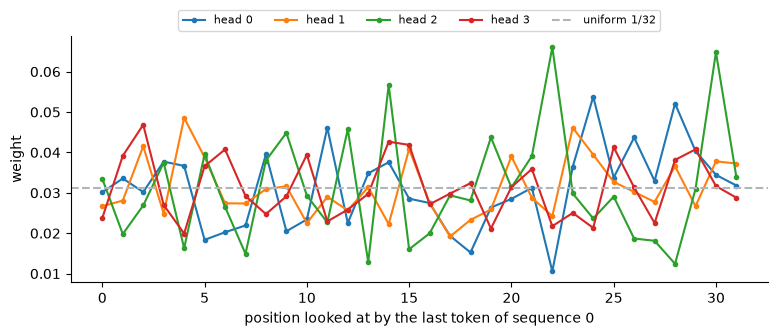

In [22]:
# Four heads of 16 or one head of 64? Same attention parameters, but how many patterns?
one = MultiHeadAttention(1, n_embd)
print(f'Attention parameters: 4 heads of 16 {sum(p.numel() for p in sa.heads.parameters()):,}, '
      f'1 head of 64 {sum(p.numel() for p in one.heads.parameters()):,}')

patterns = []
for h in sa.heads:
    k_h = h.key(x)
    scores = h.query(x) @ k_h.transpose(-2, -1) * k_h.size(-1)**-0.5
    patterns.append(F.softmax(scores.masked_fill(h.tril == 0, float('-inf')), dim=-1).detach())
gaps = [(a - b).abs().max().item() for i, a in enumerate(patterns) for b in patterns[i + 1:]]
entropies = [-(w[:, -1] * torch.log(w[:, -1])).sum(dim=-1).mean().item() for w in patterns]
cosines = [F.cosine_similarity(a.flatten(), b.flatten(), dim=0).item()
           for i, a in enumerate(head_outs) for b in head_outs[i + 1:]]
print(f'Largest gap between the weights of two heads: {max(gaps):.2f}')
print(f'Mean last-row entropy per head: {[round(e, 2) for e in entropies]}, '
      f'uniform {math.log(block_size):.2f}')
print(f'Cosine between the outputs of two heads: from {min(cosines):.3f} to {max(cosines):.3f}')

fig, ax = plt.subplots(figsize=(9, 3.2))
for h, pattern in enumerate(patterns):
    ax.plot(range(block_size), pattern[0, -1], marker='o', markersize=3, label=f'head {h}')
ax.axhline(1 / block_size, linestyle='--', color='#adb5bd', label='uniform 1/32')
ax.set_xlabel('position looked at by the last token of sequence 0')
ax.set_ylabel('weight')
ax.legend(fontsize=8, ncols=5, loc='lower center', bbox_to_anchor=(0.5, 1.0))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Four heads of 16 and one head of 64 each have 12,288 query, key and value parameters. Equal parameter counts do not establish equal runtime or memory use. The one-head module also has newly initialised weights, so this is not a shared-weight comparison.

The four existing heads differ by up to 0.42 in their attention weights, with output cosines from 0.010 to 0.085. Those cosines describe directional alignment, and the average last-row entropies of 3.41 to 3.43 remain near the uniform 3.47. Random differences do not yet demonstrate learned specialisation.


> *My conclusion:*
>
> The channel slices and worked projection explain how four heads recover 64 channels. My shape hypothesis holds, while the different random attention patterns leave their usefulness for learning unanswered. Section 9 supplies the existing training comparison.
>
> My answers to the two questions of this step:
>
> 1. The last dimension keeps each token's head outputs together. Concatenating on the batch or position axis fails the projection's input-width requirement.
> 2. Integer division loses channels when n_embd is not divisible by n_head. The initial assertion catches configurations such as five heads producing only 60 channels.


## 3. Assemble a block

I combine attention with the token-wise MLP from TP3, each inside its own pre-norm residual branch. Keeping the shape is necessary for stacking blocks, but I also need to know which input tokens can affect each output. The influence and gradient tests address those different questions.


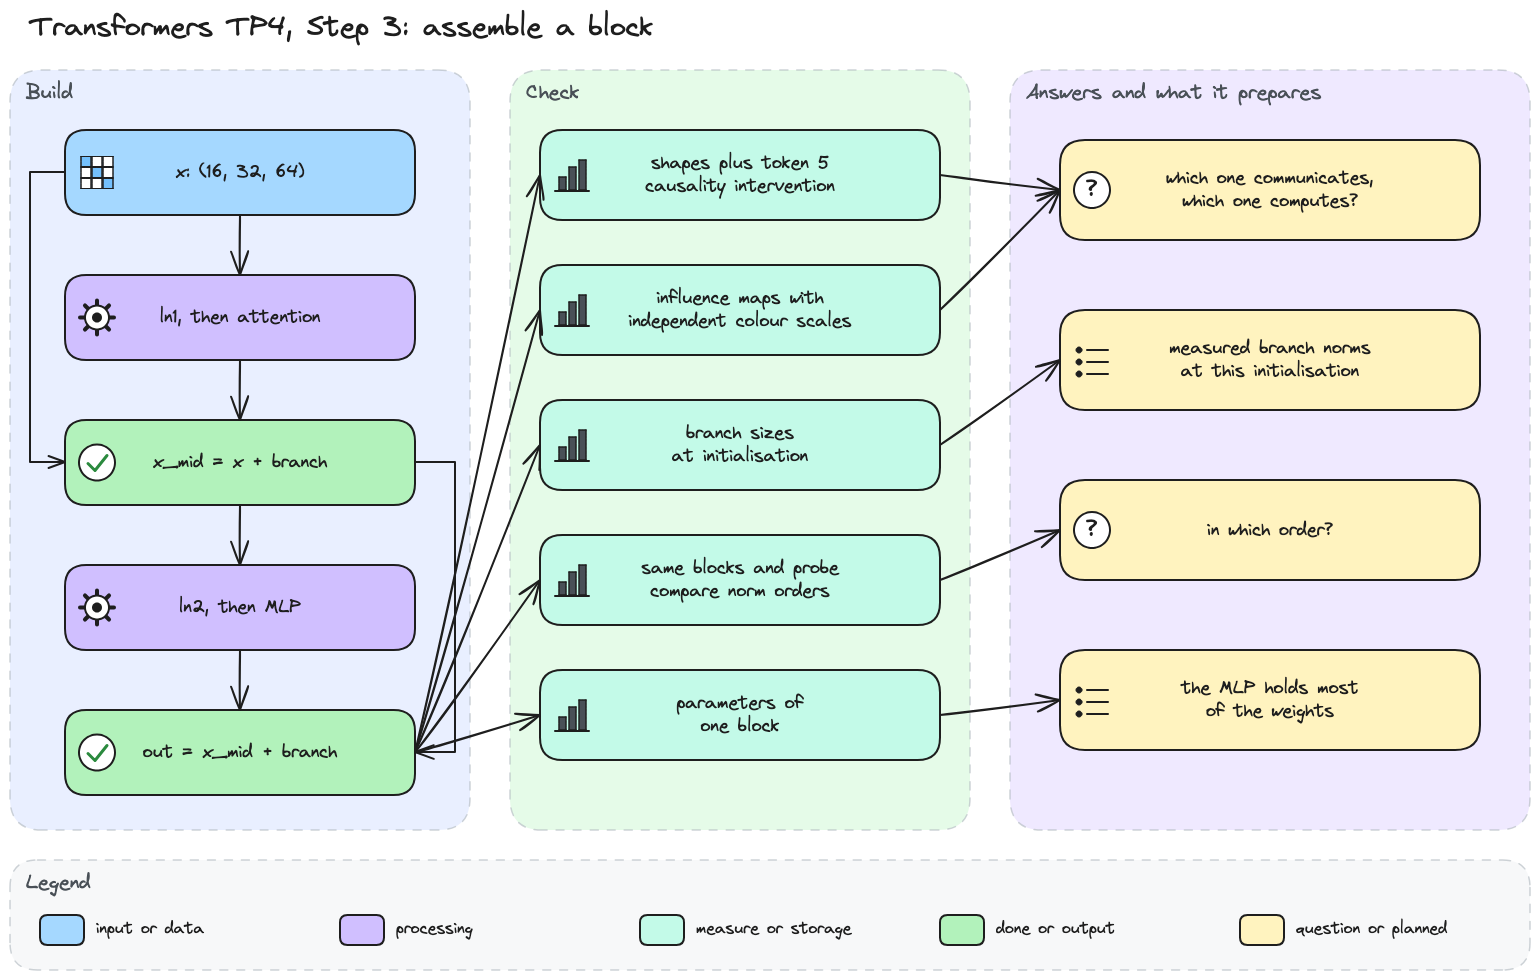

In [23]:
# Step 3 diagram: one block, attention then MLP, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step3.png', width=900))

In [24]:
# The MLP of TP3, with a dropout on its output as the existing gives it.
class FeedForward(nn.Module):
    """Linear n_embd to 4 n_embd, ReLU, Linear back to n_embd, then dropout."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [25]:
# One Transformer block: attention then MLP, each after its LayerNorm and with its residual.
class Block(nn.Module):
    """Communication by attention, then computation by the MLP, in the pre-norm order."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

I use `x = x + self.sa(self.ln1(x))`, followed by `x = x + self.ffwd(self.ln2(x))`. Each addition preserves an identity contribution alongside the branch. As TP3 showed, branch derivatives can reinforce or cancel that contribution.


In [26]:
# Does a block keep the shape and the causal rule? One block on x of shape (16, 32, 64).
torch.manual_seed(1337)
block = Block(n_embd, n_head)
x = torch.randn(batch_size, block_size, n_embd)
out = block(x)
print(f'x {tuple(x.shape)} -> block(x) {tuple(out.shape)}')

changed = x.clone()
changed[0, 5] = torch.randn(n_embd)
print(f'Token 5 replaced, rows 0 to 4 unchanged: '
      f'{torch.equal(block(changed)[0, :5], out[0, :5])}')

x (16, 32, 64) -> block(x) (16, 32, 64)
Token 5 replaced, rows 0 to 4 unchanged: True


The block preserves (16, 32, 64), and changing token 5 leaves the earlier outputs unchanged. I next inspect derivatives between token positions to distinguish attention's cross-token effects from the MLP's token-wise transformation.


attention branch, sa(ln1(x)): largest influence on another token 1.14, from a later token 0.00
MLP branch, ffwd(ln2(x)): largest influence on another token 0.00, from a later token 0.00
whole block: largest influence on another token 1.16, from a later token 0.00


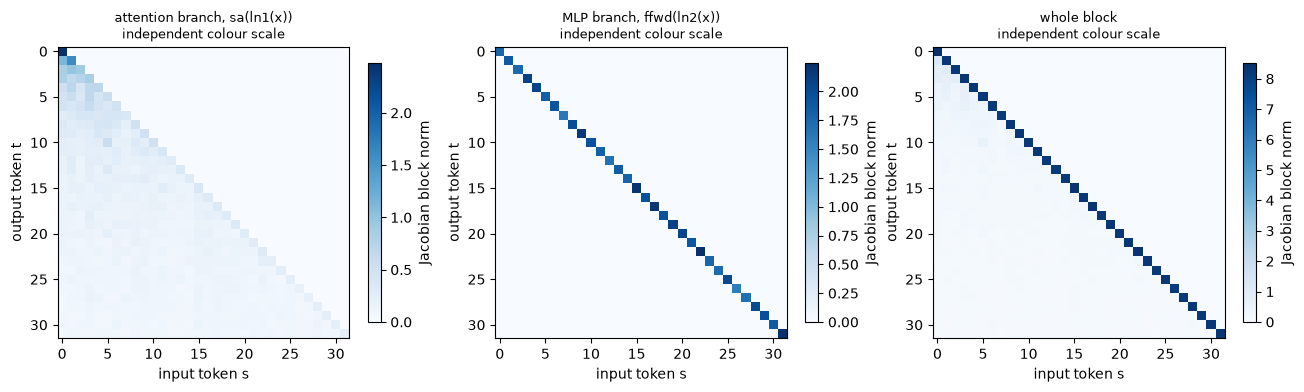

In [27]:
# Which branch talks between tokens and which computes alone? Influence maps on sequence 0.
pieces = {'attention branch, sa(ln1(x))': lambda v: block.sa(block.ln1(v[None]))[0],
          'MLP branch, ffwd(ln2(x))': lambda v: block.ffwd(block.ln2(v)),
          'whole block': lambda v: block(v[None])[0]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, piece) in zip(axes, pieces.items()):
    jacobian = torch.autograd.functional.jacobian(piece, x[0])  # (T, C, T, C)
    influence = jacobian.norm(dim=(1, 3))  # output token t, input token s
    others = influence - torch.diag(torch.diag(influence))
    print(f'{name}: largest influence on another token {others.max():.2f}, '
          f'from a later token {influence.triu(1).max():.2f}')
    image = ax.imshow(influence, cmap='Blues')
    fig.colorbar(image, ax=ax, shrink=0.7, label='Jacobian block norm')
    ax.set_title(name + '\nindependent colour scale', fontsize=9)
    ax.set_xlabel('input token s')
    ax.set_ylabel('output token t')
plt.show()

The attention branch has lower-triangular influence, reaching 1.14 between different tokens and 0.00 from future tokens at the displayed precision. The isolated MLP branch has no cross-token influence, while the whole block remains lower triangular. Each heatmap uses its own colour scale, so darker colours cannot be compared across panels.

The isolated MLP map uses `x`, while the complete block feeds that branch the stream after attention. These maps identify the pattern of dependence at the tested inputs. I next measure branch norms because a causal block can still make a large correction.


attention, ||sa(ln1(x))|| / ||x||: from 7.17% to 50.69%, mean 13.40%
MLP, ||ffwd(ln2(x))|| / ||x|| after attention: from 17.48% to 37.00%, mean 25.60%


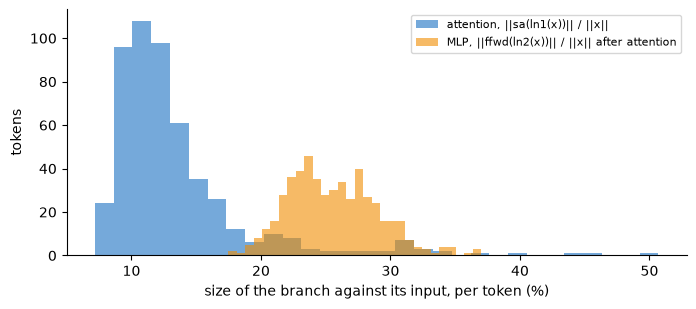

In [28]:
# How much does each branch add at initialisation? Size of each branch against its input.
attention_add = block.sa(block.ln1(x))
x_mid = x + attention_add
mlp_add = block.ffwd(block.ln2(x_mid))
shares = {'attention, ||sa(ln1(x))|| / ||x||': attention_add.norm(dim=-1) / x.norm(dim=-1),
          'MLP, ||ffwd(ln2(x))|| / ||x|| after attention':
              mlp_add.norm(dim=-1) / x_mid.norm(dim=-1)}
fig, ax = plt.subplots(figsize=(8, 3.2))
for (name, share), color in zip(shares.items(), ('#1971c2', '#f08c00')):
    share = 100 * share.flatten().detach()
    print(f'{name}: from {share.min():.2f}% to {share.max():.2f}%, mean {share.mean():.2f}%')
    ax.hist(share, bins=30, color=color, alpha=0.6, label=name)
ax.set_xlabel('size of the branch against its input, per token (%)')
ax.set_ylabel('tokens')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Attention adds 13.40% of its input norm on average, with values from 7.17% to 50.69% across tokens. The MLP adds 25.60% on average after attention, ranging from 17.48% to 37.00%. These are measurements at this initialisation and input scale, so I cannot assume every residual correction is small.

I next compare normalisation orders using the same blocks, input and fixed gradient probe. Each depth reuses a prefix of the same block list, and scaling the input by five tests sensitivity to stream magnitude.


pre-norm, x + f(ln(x)), 4 blocks: std of the stream 5.03, gradient at x / ||g|| 1.01, cosine to x 0.99
pre-norm, x + f(ln(x)), 16 blocks: std of the stream 5.10, gradient at x / ||g|| 1.02, cosine to x 0.98
post-norm, ln(x + f(x)), 4 blocks: std of the stream 1.00, gradient at x / ||g|| 0.26, cosine to x 0.82
post-norm, ln(x + f(x)), 16 blocks: std of the stream 1.00, gradient at x / ||g|| 0.22, cosine to x 0.45
no LayerNorm, x + f(x), 4 blocks: std of the stream 6.66, gradient at x / ||g|| 4.33, cosine to x 0.75
no LayerNorm, x + f(x), 16 blocks: std of the stream 16.44, gradient at x / ||g|| 8627.29, cosine to x 0.30


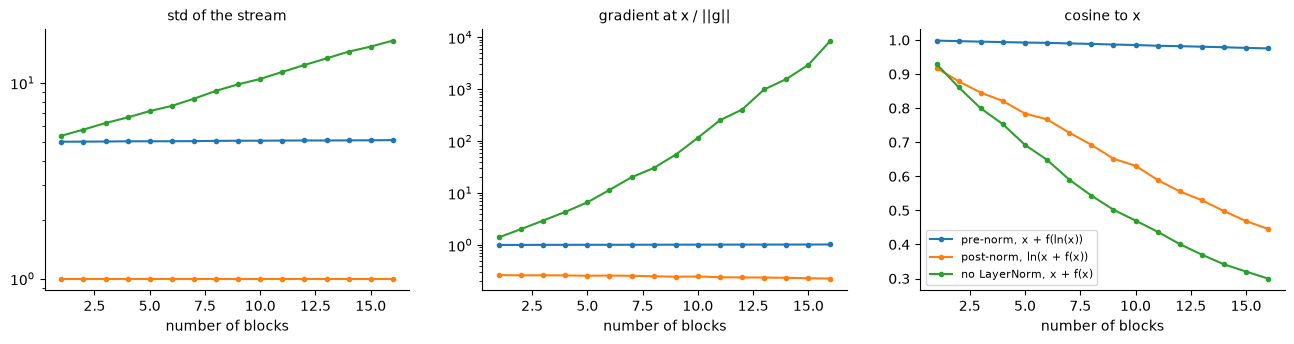

In [29]:
# In which order? Pre-norm, post-norm and no LayerNorm on 16 fresh blocks, input scaled by 5.
torch.manual_seed(RANDOM_STATE)
blocks = [Block(n_embd, n_head) for _ in range(16)]
g = torch.randn(batch_size, block_size, n_embd)  # a fixed direction, loss = (z * g).sum()
ORDERS = {'pre-norm, x + f(ln(x))': lambda z, f, ln: z + f(ln(z)),
          'post-norm, ln(x + f(x))': lambda z, f, ln: ln(z + f(z)),
          'no LayerNorm, x + f(x)': lambda z, f, ln: z + f(z)}
METRICS = ['std of the stream', 'gradient at x / ||g||', 'cosine to x']
history = {name: {metric: [] for metric in METRICS} for name in ORDERS}
for name, step in ORDERS.items():
    for depth in range(1, 17):
        start = (5 * x).detach().requires_grad_()
        z = start
        for b in blocks[:depth]:
            z = step(step(z, b.sa, b.ln1), b.ffwd, b.ln2)
        (z * g).sum().backward()
        history[name]['std of the stream'].append(z.std().item())
        history[name]['gradient at x / ||g||'].append((start.grad.norm() / g.norm()).item())
        history[name]['cosine to x'].append(
            F.cosine_similarity(z.flatten(), start.flatten(), dim=0).item())
    for depth in (4, 16):
        print(f'{name}, {depth} blocks: '
              + ', '.join(f'{metric} {history[name][metric][depth - 1]:.2f}' for metric in METRICS))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, metric in zip(axes, METRICS):
    for name in ORDERS:
        ax.plot(range(1, 17), history[name][metric], marker='o', markersize=3, label=name)
    ax.set_xlabel('number of blocks')
    ax.set_title(metric, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[:2]:
    ax.set_yscale('log')
axes[2].legend(fontsize=8)
plt.show()

At the printed depths 4 and 16, pre-norm gives stream standard deviations of 5.03 and 5.10 and gradient ratios of 1.01 and 1.02. At depth 16, its cosine to the input is 0.98. That cosine measures alignment, while the gradient probe tests local sensitivity in one chosen direction.

At depth 16, post-norm gives a gradient ratio of 0.22, compared with 8627.29 without LayerNorm. This supports the pre-norm choice for the tested weights and input, without establishing training success or a lower bound on gradients. LayerNorm uses population variance plus epsilon, then learned affine parameters, so rounded standard deviation one is not an exact general identity.


attention sa: 16,448 parameters, 33.03% of the block
MLP ffwd: 33,088 parameters, 66.45% of the block
ln1: 128 parameters, 0.26% of the block
ln2: 128 parameters, 0.26% of the block
One block: 49,792 parameters, 4 blocks: 199,168


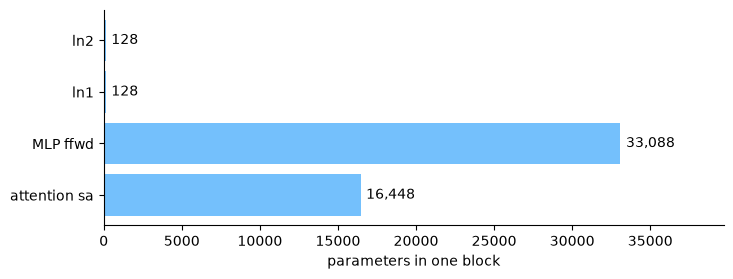

In [30]:
# Where are the weights of a block? Parameters of each part, for one block and for four.
parts = {'attention sa': block.sa, 'MLP ffwd': block.ffwd, 'ln1': block.ln1, 'ln2': block.ln2}
counts = {name: sum(p.numel() for p in part.parameters()) for name, part in parts.items()}
total = sum(p.numel() for p in block.parameters())
for name, count in counts.items():
    print(f'{name}: {count:,} parameters, {100 * count / total:.2f}% of the block')
print(f'One block: {total:,} parameters, {n_layer} blocks: {n_layer * total:,}')

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(list(counts), list(counts.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{count:,}' for count in counts.values()], padding=4)
ax.set_xlim(0, max(counts.values()) * 1.2)
ax.set_xlabel('parameters in one block')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

One block has 49,792 parameters, including 33,088 in the MLP and 16,448 in attention. The four blocks therefore contain 199,168 parameters. Most weights transform each token individually, and these counts do not measure computational cost or model quality.


> *My conclusion:*
>
> The block preserves shape and causality in the checks, while the influence maps distinguish its two branches. The norm and gradient results support the chosen order locally. They do not show how the network will learn.
>
> My answers to the two questions of this step:
>
> 1. I apply LayerNorm before each branch, then add its output to the residual stream. The shared-block comparison kept the fixed gradient probe near its input norm with this order.
> 2. Attention mixes information between visible tokens. The MLP transforms each token separately, as its diagonal influence map shows.


## 4. Define the layers of the model

I replace TP1's direct lookup of next-character scores with embeddings, contextual blocks and an output projection. I keep the name `BigramLanguageModel` for compatibility, although this class now implements a Transformer. Before defining its forward pass, I inspect the shapes, parameter allocation and initial scales.


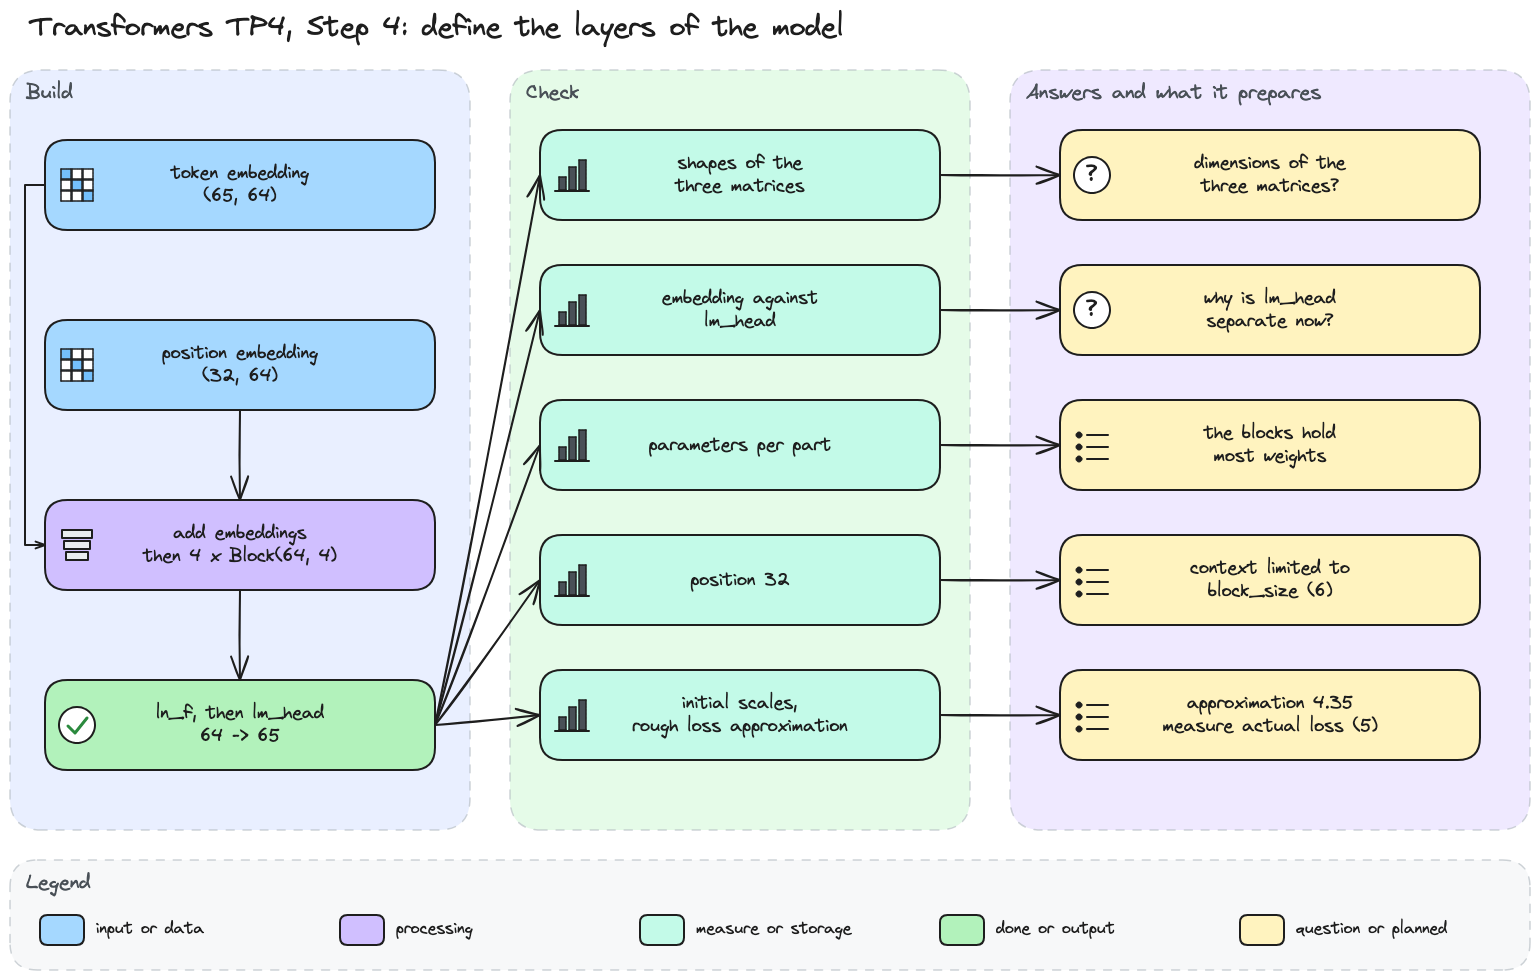

In [31]:
# Step 4 diagram: embeddings, blocks and unembedding, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step4.png', width=900))

In [32]:
# The layers of the model: token and position embeddings, the blocks, then the unembedding.
class BigramLanguageModel(nn.Module):
    """Character-level Transformer: embeddings, n_layer blocks, final LayerNorm and lm_head."""

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

Both embeddings produce n_embd channels, and `lm_head` maps those channels to one score per character. I define the layers before attaching `forward` and `generate`, so I can check their dimensions separately.


In [33]:
# Build the model on the device and read the shapes of its three matrices.
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print(f'token_embedding_table: {tuple(model.token_embedding_table.weight.shape)}')
print(f'position_embedding_table: {tuple(model.position_embedding_table.weight.shape)}')
print(f'lm_head: weight {tuple(model.lm_head.weight.shape)}, '
      f'bias {tuple(model.lm_head.bias.shape)}')
print(f'blocks: {len(model.blocks)} x {type(model.blocks[0]).__name__}')

token_embedding_table: (65, 64)
position_embedding_table: (32, 64)
lm_head: weight (65, 64), bias (65,)
blocks: 4 x Block


The token embedding has the shape (65, 64), one row of 64 numbers per character. The position embedding has (32, 64), one row per place in a context of block_size. `lm_head` stores its weight as (65, 64) with a bias of 65, since `nn.Linear` keeps one row per output, so it maps 64 channels to 65 scores. Between them sit the 4 blocks of section 3.

In [34]:
# Can the embedding still give the logits, as my TP1 table did? Shapes and the two weights.
token_vectors = model.token_embedding_table(xb)
print(f'Token embedding of xb: {tuple(token_vectors.shape)}, {n_embd} numbers per token, '
      f'{vocab_size} needed for the logits')
print(f'lm_head on these vectors: {tuple(model.lm_head(token_vectors).shape)}')
embedding_weight, head_weight = model.token_embedding_table.weight, model.lm_head.weight
print(f'Same shape: {embedding_weight.shape == head_weight.shape}, '
      f'same tensor: {embedding_weight.data_ptr() == head_weight.data_ptr()}')
cosine = F.cosine_similarity(embedding_weight, head_weight, dim=1).abs().max()
print(f'Largest absolute cosine between row i of the two matrices: {cosine:.2f}')

Token embedding of xb: (16, 32, 64), 64 numbers per token, 65 needed for the logits
lm_head on these vectors: (16, 32, 65)
Same shape: True, same tensor: False
Largest absolute cosine between row i of the two matrices: 0.24


The embedding gives 64 channels per token, while `lm_head` produces the 65 character scores. Its matrix and the token embedding have the same shape but separate storage, with maximum absolute row cosine 0.24.

At this stage both matrices are untrained. Their roles are to represent input identities and read contextual vectors, but the random values do not demonstrate learned meanings.


token embedding: 4,160 parameters, 1.98%
position embedding: 2,048 parameters, 0.98%
4 blocks: 199,168 parameters, 94.96%
ln_f: 128 parameters, 0.06%
lm_head: 4,225 parameters, 2.01%
Total: 209,729 parameters, 49.6 times my TP1 bigram (4,225)


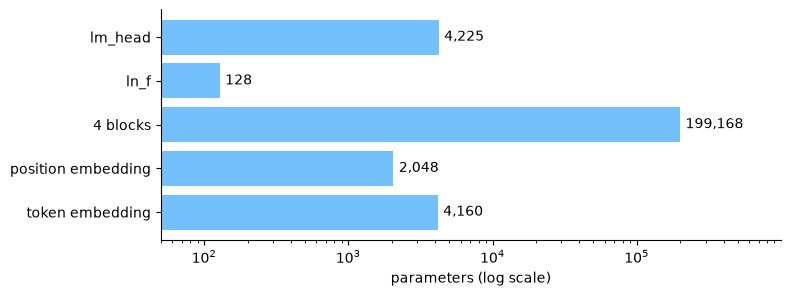

In [35]:
# Where are the weights of the model? Parameters of each part, against my TP1 bigram.
parts = {'token embedding': model.token_embedding_table,
         'position embedding': model.position_embedding_table,
         f'{n_layer} blocks': model.blocks, 'ln_f': model.ln_f, 'lm_head': model.lm_head}
counts = {name: sum(p.numel() for p in part.parameters()) for name, part in parts.items()}
total = sum(p.numel() for p in model.parameters())
TP1_BIGRAM = 4225  # parameters of my TP1 table, 65 x 65
for name, count in counts.items():
    print(f'{name}: {count:,} parameters, {100 * count / total:.2f}%')
print(f'Total: {total:,} parameters, {total / TP1_BIGRAM:.1f} times my TP1 bigram '
      f'({TP1_BIGRAM:,})')

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(list(counts), list(counts.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{count:,}' for count in counts.values()], padding=4)
ax.set_xscale('log')
ax.set_xlim(50, max(counts.values()) * 5)
ax.set_xlabel('parameters (log scale)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The model has 209,729 parameters, 49.6 times TP1's bigram table. Its four blocks hold 94.96% of them, including the token-wise MLP weights. Any later gain over TP1 combines changes in context, capacity and training, so this comparison cannot isolate attention's contribution.


In [36]:
# How far can the model read? The position table for positions 0 to 31, then position 32.
positions = torch.arange(block_size, device=device)
print(f'Positions 0 to {block_size - 1}: '
      f'{tuple(model.position_embedding_table(positions).shape)}')
try:
    model.position_embedding_table(torch.tensor([block_size], device=device))
except IndexError as error:
    print(f'Position {block_size}: {error}')

Positions 0 to 31: (32, 64)
Position 32: index out of range in self


The position table accepts indices 0 to 31 and rejects position 32. Generation must therefore crop its context before lookup. I next inspect the output scale because random logits need not give the uniform reference loss.


In [37]:
# What will the first loss be? The scales of the starting weights and of the first logits.
rows = model.token_embedding_table.weight
print(f'Token embedding rows: std {rows.std():.2f}, mean norm {rows.norm(dim=1).mean():.2f}')
print(f'lm_head weights: std {model.lm_head.weight.std():.3f}')

torch.manual_seed(RANDOM_STATE)
logits = model.lm_head(model.ln_f(torch.randn(10000, n_embd, device=device)))
sigma = logits.std().item()
targets = torch.randint(vocab_size, (10000,), device=device)
print(f'Logits on normalised vectors: std {sigma:.2f}')
print(f'ln({vocab_size}) + sigma^2 / 2 = {math.log(vocab_size) + sigma**2 / 2:.2f}')
print(f'Cross-entropy of these logits on random targets: {F.cross_entropy(logits, targets):.2f}')

Token embedding rows: std 1.00, mean norm 7.95
lm_head weights: std 0.073
Logits on normalised vectors: std 0.58
ln(65) + sigma^2 / 2 = 4.35
Cross-entropy of these logits on random targets: 4.34


The token embedding has aggregate standard deviation 1.00 and mean row norm 7.95, while the output weights have standard deviation 0.073. On synthetic normalised inputs, the logits have standard deviation 0.58.

The approximation ln(65) + σ²/2 gives 4.35, compared with measured cross-entropy 4.34 on random targets. It assumes approximately Gaussian centred scores and replaces the exponential sum by its expectation. The synthetic inputs and uniformly random targets differ from corpus predictions, so I treat this as a rough reference for section 5.


> *My conclusion:*
>
> The layers have compatible widths, and the parameter count makes the capacity change from TP1 explicit. The initial-scale experiment suggests checking a loss above the uniform reference. I now need the full forward pass to measure it on corpus targets.
>
> My answers to the two questions of this step:
>
> 1. The token and position tables have shapes (65, 64) and (32, 64). The output weight has shape (65, 64), with a bias of 65.
> 2. The embedding represents input characters before the blocks. The separate output projection reads their contextual representations and produces next-character scores.


## 5. Write the forward pass and the loss

I want to check both the tensor path and the meaning of one prediction. I add token and position embeddings, apply the blocks, then convert the final representations into character scores. A worked target loss will connect these operations to the quantity training minimises.


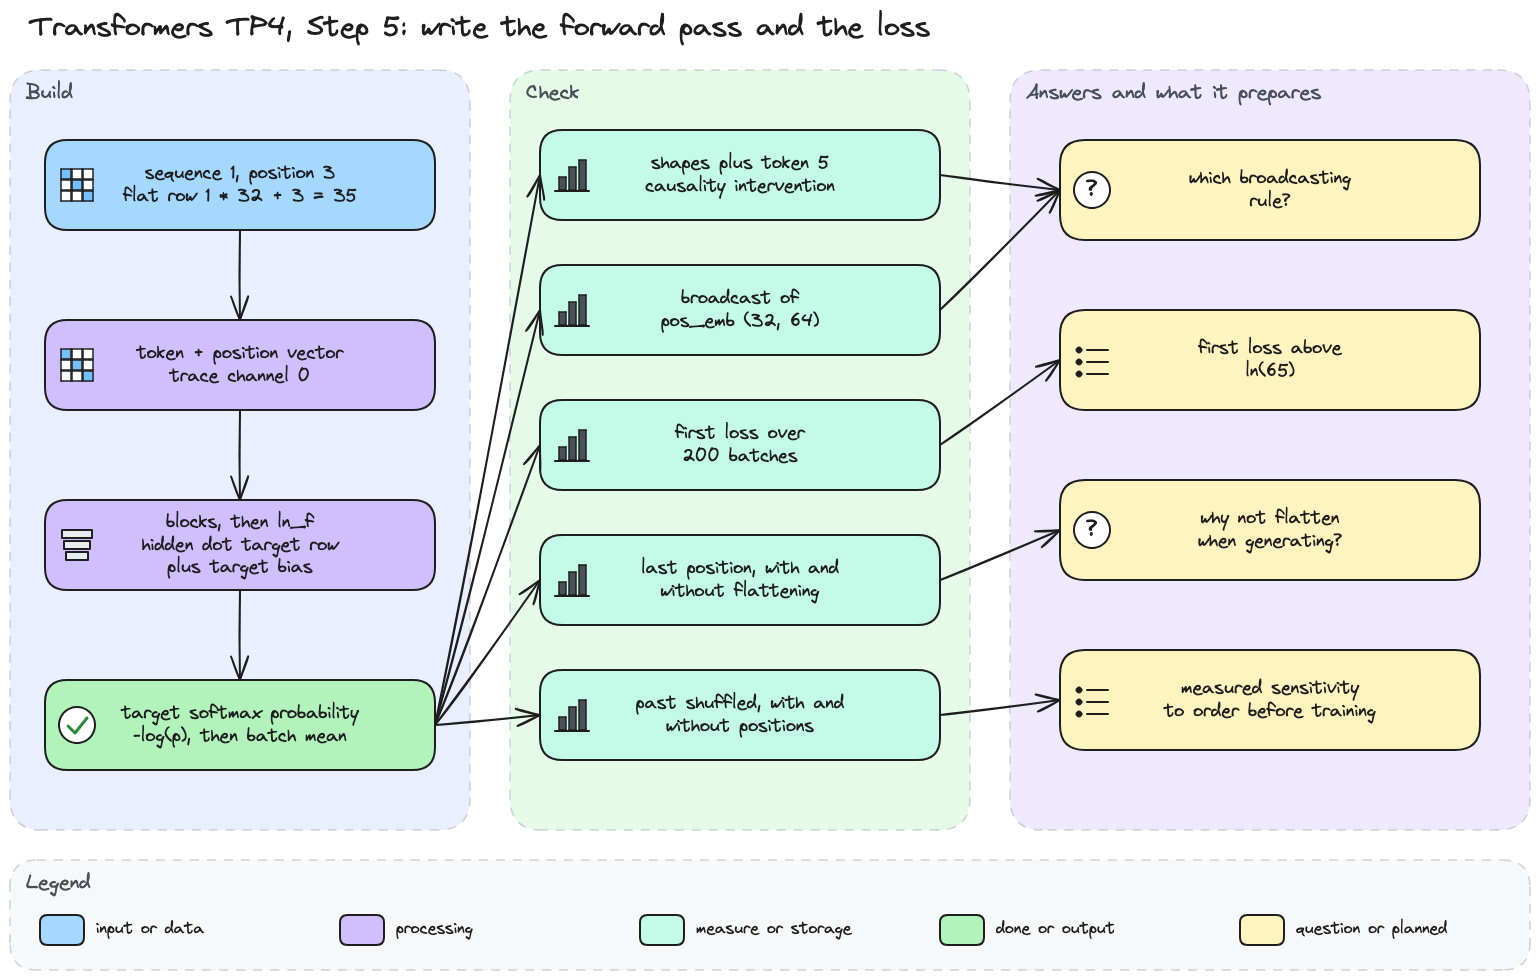

In [38]:
# Step 5 diagram: the forward pass from ids to loss, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step5.png', width=900))

In [39]:
# The forward pass: embeddings, blocks, logits, and the loss only when targets are given.
def forward(self, idx, targets=None):
    """Logits for the ids idx, and the cross-entropy when targets are given."""
    B, T = idx.shape

    tok_emb = self.token_embedding_table(idx)    # (B,T,n_embd)
    pos = torch.arange(T, device=idx.device)      # (T,)
    pos_emb = self.position_embedding_table(pos)  # (T,n_embd)

    x = tok_emb + pos_emb                         # (B,T,C)
    x = self.blocks(x)                            # (B,T,C)
    x = self.ln_f(x)                              # (B,T,C)
    logits = self.lm_head(x)                      # (B,T,vocab_size)

    if targets is None:
        loss = None
    else:
        logits = logits.reshape(B*T, vocab_size)  # (B*T,vocab_size)
        targets = targets.reshape(B*T)            # (B*T,)
        loss = F.cross_entropy(logits, targets)
    return logits, loss


BigramLanguageModel.forward = forward  # added to the class of section 4

The sum `tok_emb + pos_emb` gives every sequence the same position vectors. I flatten logits and targets in the same order for `F.cross_entropy`. Keeping the three-dimensional logits when targets are absent makes the last position of each sequence easy to select.


In [40]:
# Do the shapes follow my comments? One batch through the model, without then with targets.
tok_emb = model.token_embedding_table(xb)
pos_emb = model.position_embedding_table(torch.arange(block_size, device=device))
print(f'idx {tuple(xb.shape)}, tok_emb {tuple(tok_emb.shape)}, pos_emb {tuple(pos_emb.shape)}, '
      f'x {tuple((tok_emb + pos_emb).shape)}')
logits, loss = model(xb)
print(f'Without targets: logits {tuple(logits.shape)}, loss {loss}')
flat_logits, loss = model(xb, yb)
print(f'With targets: logits {tuple(flat_logits.shape)}, targets {tuple(yb.reshape(-1).shape)}, '
      f'loss {loss.item():.2f}')

changed = xb.clone()
changed[0, 5] = (changed[0, 5] + 1) % vocab_size  # another character at position 5
print(f'Token 5 replaced, logits of rows 0 to 4 unchanged: '
      f'{torch.equal(model(changed)[0][0, :5], logits[0, :5])}')

idx (16, 32), tok_emb (16, 32, 64), pos_emb (32, 64), x (16, 32, 64)
Without targets: logits (16, 32, 65), loss None
With targets: logits (512, 65), targets (512,), loss 4.39
Token 5 replaced, logits of rows 0 to 4 unchanged: True


The model returns (16, 32, 65) logits without targets and (512, 65) with targets, giving mean loss 4.39 on this batch. Changing token 5 leaves earlier logits unchanged. I now verify broadcasting explicitly before following one sequence-position pair through the loss.


In [41]:
# Which rule lets (16, 32, 64) + (32, 64) work? The sum against an explicit copy per sequence.
x_sum = tok_emb + pos_emb
x_explicit = tok_emb + pos_emb.unsqueeze(0).expand(batch_size, -1, -1)
print(f'pos_emb {tuple(pos_emb.shape)} read as (1, 32, 64), sum {tuple(x_sum.shape)}')
print(f'Same as copying pos_emb for each sequence: {torch.equal(x_sum, x_explicit)}')
print(f'Each sequence b gets tok_emb[b] + pos_emb: '
      f'{all(torch.equal(x_sum[b], tok_emb[b] + pos_emb) for b in range(batch_size))}')
try:
    tok_emb + pos_emb.T
except RuntimeError as error:
    print(f'pos_emb.T {tuple(pos_emb.T.shape)}: {error}')

pos_emb (32, 64) read as (1, 32, 64), sum (16, 32, 64)
Same as copying pos_emb for each sequence: True
Each sequence b gets tok_emb[b] + pos_emb: True
pos_emb.T (64, 32): The size of tensor a (64) must match the size of tensor b (32) at non-singleton dimension 2


Broadcasting treats (32, 64) position embeddings as (1, 32, 64), sharing them across all 16 sequences. The sum equals explicit expansion, while transposing the position matrix makes the channel dimensions incompatible.

For the worked prediction, I keep sequence 1 and position 3 from this batch. Its flattened index is 1 × 32 + 3, so I can check the target against both tensor layouts.


In [42]:
# Follow one existing sequence-position pair from embedding addition to cross-entropy.
demo_b, demo_t = 1, 3
demo_flat_row = demo_b * block_size + demo_t
demo_target = yb[demo_b, demo_t].detach()
demo_stream = tok_emb.detach() + pos_emb.detach()
with torch.no_grad():
    demo_hidden = model.ln_f(model.blocks(demo_stream)).detach()
demo_output_row = model.lm_head.weight[demo_target].detach()
demo_output_bias = model.lm_head.bias[demo_target].detach()
demo_target_logit = demo_hidden[demo_b, demo_t] @ demo_output_row + demo_output_bias
demo_scores = flat_logits[demo_flat_row].detach()
demo_probability = F.softmax(demo_scores, dim=-1)[demo_target]
demo_penalty = -demo_probability.log()
demo_losses = F.cross_entropy(flat_logits.detach(), yb.reshape(-1), reduction='none')
assert demo_flat_row == 35
assert torch.equal(demo_scores, logits[demo_b, demo_t].detach())
assert torch.allclose(demo_target_logit, demo_scores[demo_target], atol=1e-7, rtol=1e-5)
assert torch.allclose(demo_penalty, demo_losses[demo_flat_row])
assert torch.allclose(demo_losses.mean(), loss.detach())
print(f'Visible prefix {decode(xb[demo_b, :demo_t + 1].tolist())!r}, '
      f'target {itos[demo_target.item()]!r}, flattened row {demo_flat_row}')
print(f'Embedding channel 0: {tok_emb[demo_b, demo_t, 0].detach():.6f} '
      f'+ {pos_emb[demo_t, 0].detach():.6f} = {demo_stream[demo_b, demo_t, 0]:.6f}')
print(f'Target logit: hidden dot output row '
      f'{(demo_hidden[demo_b, demo_t] @ demo_output_row):.6f} '
      f'+ bias {demo_output_bias:.6f} = {demo_target_logit:.6f}')
print(f'Target probability {demo_probability:.6f}, -log(p) {demo_penalty:.6f}, '
      f'PyTorch {demo_losses[demo_flat_row]:.6f}')
print(f'Mean of {demo_losses.numel()} position losses {demo_losses.mean():.6f}, '
      f'existing batch loss {loss.detach():.6f}')


Visible prefix 'k an', target ' ', flattened row 35
Embedding channel 0: -1.957165 + -0.501453 = -2.458618
Target logit: hidden dot output row -0.307056 + bias -0.091985 = -0.399041
Target probability 0.007939, -log(p) 4.835994, PyTorch 4.835994
Mean of 512 position losses 4.390262, existing batch loss 4.390261


The target probability turns into a larger penalty when the model assigns it less probability. The single penalty and batch mean agree with PyTorch within tolerance.

The last displayed digits can differ because floating-point sums are grouped differently. I now measure several random batches to see how much the initial loss depends on the sampled text.


train: mean 4.41, std 0.02, from 4.35 to 4.47
val: mean 4.40, std 0.03, from 4.33 to 4.47
ln(65) = 4.17, section 4 approximation 4.35
Logit std on a real batch: 0.59, ln(65) + sigma^2 / 2 = 4.35
On xb: mean log-sum-exp 4.36 minus mean target logit -0.034 = 4.39


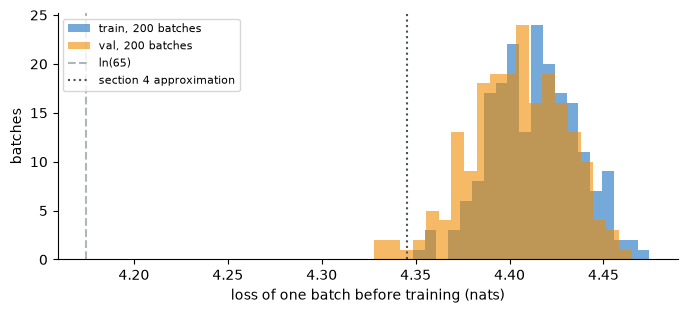

In [43]:
# How far is the first loss from ln(65)? The loss on 200 batches of each split, before training.
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    first_losses = {split: torch.tensor([model(*get_batch(split))[1].item() for _ in range(200)])
                    for split in ('train', 'val')}
    real_logits = model(xb)[0]
    real_sigma = real_logits.std().item()
    log_sum_exp = torch.logsumexp(real_logits, dim=-1).mean()
    target_logit = real_logits.gather(-1, yb.unsqueeze(-1)).mean()  # logit of the true next char
for split, values in first_losses.items():
    print(f'{split}: mean {values.mean():.2f}, std {values.std():.2f}, '
          f'from {values.min():.2f} to {values.max():.2f}')
print(f'ln({vocab_size}) = {math.log(vocab_size):.2f}, '
      f'section 4 approximation {math.log(vocab_size) + sigma**2 / 2:.2f}')
print(f'Logit std on a real batch: {real_sigma:.2f}, '
      f'ln({vocab_size}) + sigma^2 / 2 = {math.log(vocab_size) + real_sigma**2 / 2:.2f}')
print(f'On xb: mean log-sum-exp {log_sum_exp:.2f} minus mean target logit {target_logit:.3f} '
      f'= {log_sum_exp - target_logit:.2f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for (split, values), color in zip(first_losses.items(), ('#1971c2', '#f08c00')):
    ax.hist(values, bins=20, color=color, alpha=0.6, label=f'{split}, 200 batches')
ax.axvline(math.log(vocab_size), linestyle='--', color='#adb5bd', label='ln(65)')
ax.axvline(math.log(vocab_size) + sigma**2 / 2, linestyle=':', color='#495057',
           label='section 4 approximation')
ax.set_xlabel('loss of one batch before training (nats)')
ax.set_ylabel('batches')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Across 200 batches per split, the untrained losses average 4.41 on training data and 4.40 on validation. The pooled displayed range is 4.33 to 4.47, above the uniform reference 4.17. My rough approximation of 4.35 does not fully explain the real predictions.

On `xb`, the mean log-sum-exp is 4.36 and the mean target logit is -0.034, giving loss 4.39. I revise my initial hypothesis because an untrained model can assign unequal random probabilities. Equal logits would give the uniform reference, whereas absence of learned preferences does not imply equal logits.


In [44]:
# Why keep (B, T, vocab_size) when generating? The last position, read in both layouts.
with torch.no_grad():
    logits, _ = model(xb)
last = logits[:, -1, :]
flat = logits.reshape(batch_size * block_size, vocab_size)
rows = [b * block_size + block_size - 1 for b in range(batch_size)]
print(f'logits {tuple(logits.shape)} -> logits[:, -1, :] {tuple(last.shape)}, one row per sequence')
print(f'Flattened {tuple(flat.shape)}: rows b x 32 + 31 give the same rows '
      f'{torch.equal(flat[rows], last)}')
print(f'flat[-1] alone is the last position of sequence {batch_size - 1} only: '
      f'{torch.equal(flat[-1], last[-1])}')

context = torch.zeros((1, 1), dtype=torch.long, device=device)
logits_start, loss_start = model(context)
print(f'Generation context {tuple(context.shape)}: logits {tuple(logits_start.shape)}, '
      f'loss {loss_start}')

logits (16, 32, 65) -> logits[:, -1, :] (16, 65), one row per sequence
Flattened (512, 65): rows b x 32 + 31 give the same rows True
flat[-1] alone is the last position of sequence 15 only: True
Generation context (1, 1): logits (1, 1, 65), loss None


`logits[:, -1, :]` selects one prediction per sequence. After flattening, those rows are at b × 32 + 31, and `flat[-1]` selects only the final sequence. Either layout can represent the same scores if I index it correctly.

I next shuffle the past while holding the final token fixed, reusing the same weights and block prefixes. Comparing with and without position vectors tests where order sensitivity enters this untrained model.


1 block, positions False: largest change of the last output 0.000
2 blocks, positions False: largest change of the last output 0.100
4 blocks, positions False: largest change of the last output 0.155
1 block, positions True: largest change of the last output 0.043
2 blocks, positions True: largest change of the last output 0.075
4 blocks, positions True: largest change of the last output 0.180


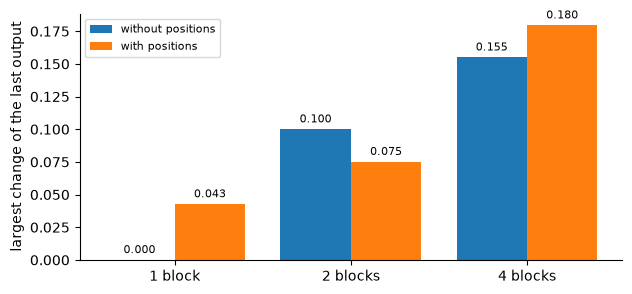

In [45]:
# Does the model see the order? The past of sequence 0 shuffled, with and without positions.
torch.manual_seed(RANDOM_STATE)
order = torch.cat([torch.randperm(block_size - 1), torch.tensor([block_size - 1])])
sequences = {'original': xb[:1], 'past shuffled': xb[:1, order]}
positions = model.position_embedding_table(torch.arange(block_size, device=device))
gaps = {}
with torch.no_grad():
    for use_positions in (False, True):
        for depth in (1, 2, 4):
            last = {name: model.blocks[:depth](model.token_embedding_table(seq)
                                                + positions * use_positions)[0, -1]
                    for name, seq in sequences.items()}
            gaps[(use_positions, depth)] = (last['original'] - last['past shuffled']).abs().max()
            print(f'{depth} block{"s" * (depth > 1)}, positions {use_positions}: '
                  f'largest change of the last output {gaps[(use_positions, depth)]:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
for offset, use_positions in ((-0.2, False), (0.2, True)):
    values = [gaps[(use_positions, depth)].item() for depth in (1, 2, 4)]
    bars = ax.bar([i + offset for i in range(3)], values, 0.4,
                  label='with positions' if use_positions else 'without positions')
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=3, fontsize=8)
ax.set_xticks(range(3), ['1 block', '2 blocks', '4 blocks'])
ax.set_ylabel('largest change of the last output')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With one block and no position vectors, the final output difference rounds to 0.000 when the visible past is permuted and the final query stays fixed. Adding positions gives a difference of 0.043. This is evidence of numerical order sensitivity, without demonstrating learned use of positions.

Without positions, two and four blocks give differences of 0.100 and 0.155. Earlier tokens now carry representations of their own causal prefixes, which the permutation changes. This order dependence comes from the prefix structure and does not imply access to future tokens.


> *My conclusion:*
>
> The worked target connects embedding addition, the output projection and cross-entropy, while the batch mean combines all position losses. The measured initial loss revises my uniform-prediction assumption. The permutation test establishes order sensitivity under its specific controls, before any learning.
>
> My answers to the two questions of this step:
>
> 1. Broadcasting supplies the same position matrix to every sequence, matching explicit expansion.
> 2. Generation needs the last row from each sequence and no target loss. Keeping (B, T, vocab_size) makes that selection direct, although a correctly indexed flat layout contains the same scores.


## 6. Generate with a limited context

I feed each sampled character back into the context to turn predictions into text. Before reading a trained sample, I need a baseline and checks on cropping, gradient tracking and decoding. I keep the initial model fixed throughout these comparisons.


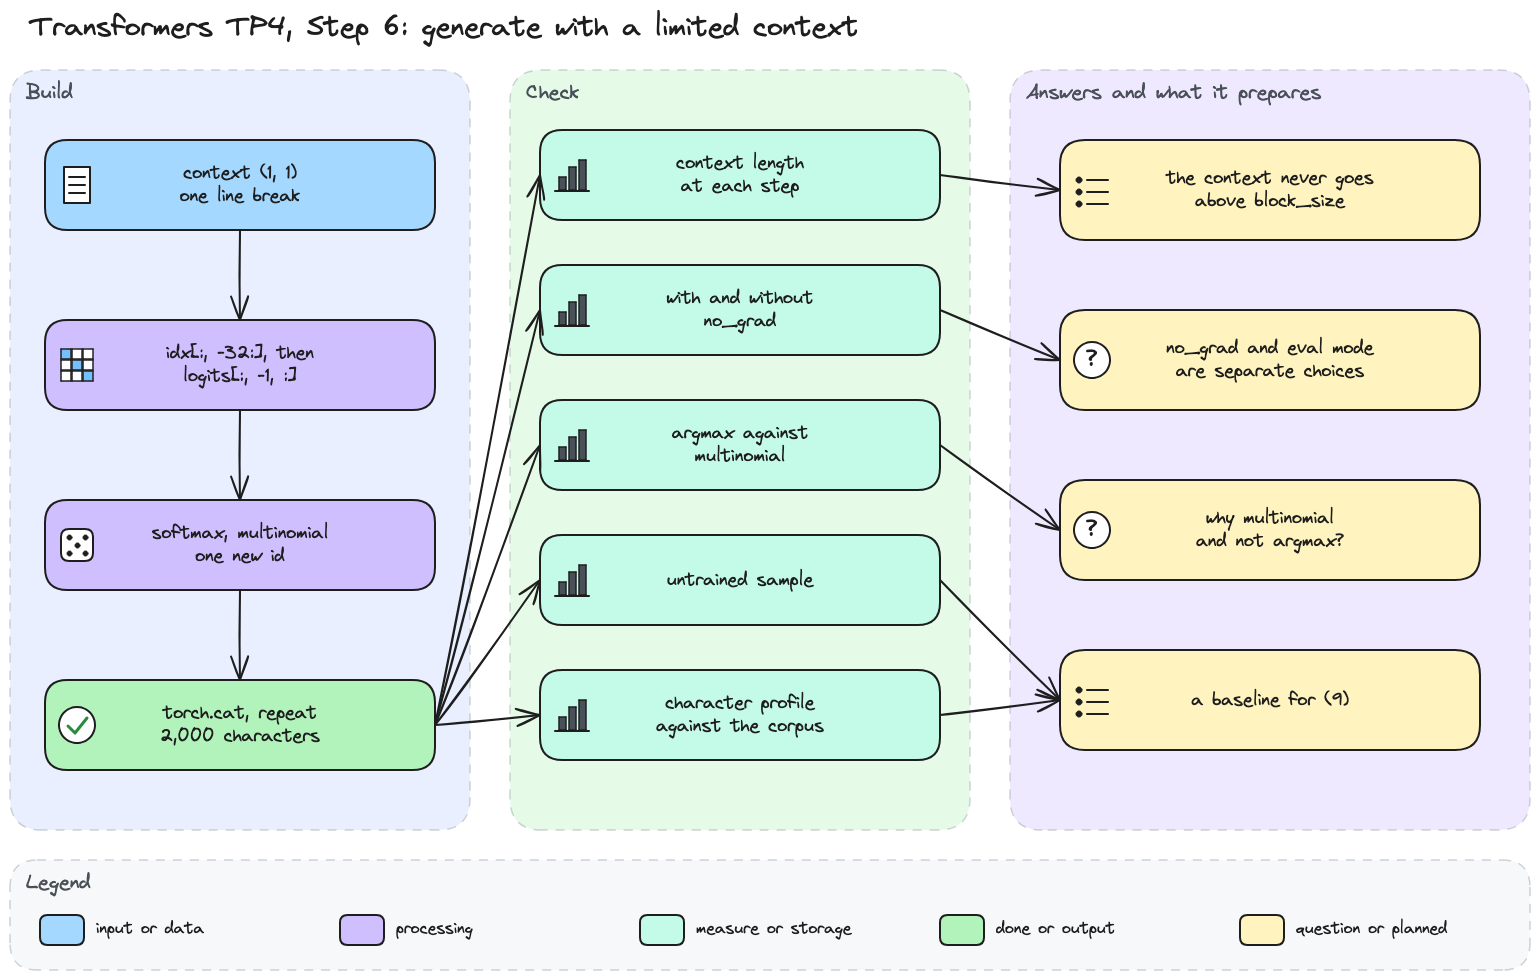

In [46]:
# Step 6 diagram: generation with a context cut to block_size, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step6.png', width=900))

In [47]:
# Generation: cut the context to block_size, predict the last position, sample, append.
@torch.no_grad()
def generate(self, idx, max_new_tokens):
    """Append max_new_tokens sampled ids to idx, one at a time."""
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]          # (B, at most block_size)
        logits, _ = self(idx_cond)               # (B,T,vocab_size)

        logits = logits[:, -1, :]                # (B,vocab_size)
        probs = F.softmax(logits, dim=-1)        # (B,vocab_size)
        idx_next = torch.multinomial(
            probs, num_samples=1
        )                                        # (B,1)
        idx = torch.cat((idx, idx_next), dim=1)  # (B,T+1)
    return idx


BigramLanguageModel.generate = generate  # added to the class of section 4

I use `idx[:, -block_size:]` to respect the position table and `logits[:, -1, :]` to predict the next character. Multinomial sampling draws from that row's softmax probabilities. `no_grad` suppresses gradient tracking, while the module's training or evaluation mode remains a separate setting.


In [48]:
# What does the model write before training? 2,000 characters from a single line break.
torch.manual_seed(RANDOM_STATE)  # the same sample at every run
context = torch.zeros((1, 1), dtype=torch.long, device=device)  # id 0 is the line break
untrained_ids = model.generate(context, max_new_tokens=2000)
untrained_text = decode(untrained_ids[0].tolist())
print(f'Output: {tuple(untrained_ids.shape)}, distinct characters: {len(set(untrained_text))}')
print(untrained_text[:300])

Output: (1, 2001), distinct characters: 65

v:sDYqLMfs
vdfCWN:$wP &IAW:YGdn.,pSzoWDnqJLnmc.p AVyMe?zaXpEpedeVaFhgUX!qP3HRWq$k-
tCgoDGkp,gRl3AJ?i
uwF!SWTiE'u
ceWAJA3 
KmUpQcf:U&FaD'&$RLUzJhDctR!qM?bNy:k-cf?g O?WTz,hNPJnHWXq?fc,uEu?LU.U&hpVp:,?oqcAW?EGcUdHPRThFpuEXFOoHNzCNLhCg;mWlK,uFL
.ceVMN MnTpYfk.Mm
aaV:,FI
sJ-qvbOjXbQquc.Ay3IbGTTNYJef-s b


The output contains the initial line break and 2,000 generated characters, using all 65 characters. The displayed fragment mixes punctuation, capitals and fragments without coherent sentences. I keep it as the pre-training sample and next inspect the context actually passed to the model.


Context length at steps 1, 32, 33 and 100: 1, 32, 32, 32
Without the cut, step 33 with a context of 33 ids fails: index out of range in self


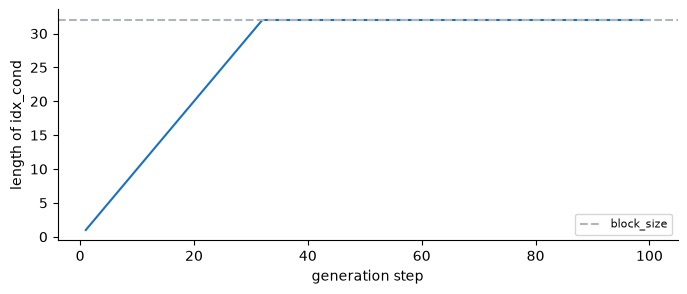

In [49]:
# How long is the context at each step? A hook on the token embedding, then a loop with no cut.
lengths = []
hook = model.token_embedding_table.register_forward_hook(
    lambda module, inputs, output: lengths.append(inputs[0].shape[1]))
model.generate(context, max_new_tokens=100)
hook.remove()
print(f'Context length at steps 1, 32, 33 and 100: '
      f'{lengths[0]}, {lengths[31]}, {lengths[32]}, {lengths[99]}')

idx = context
try:
    with torch.no_grad():
        for step in range(1, 101):
            logits, _ = model(idx)  # the whole context, no cut to block_size
            idx_next = torch.multinomial(F.softmax(logits[:, -1, :], dim=-1), num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
except IndexError as error:
    print(f'Without the cut, step {step} with a context of {idx.shape[1]} ids fails: {error}')

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, len(lengths) + 1), lengths, color='#1971c2')
ax.axhline(block_size, linestyle='--', color='#adb5bd', label='block_size')
ax.set_xlabel('generation step')
ax.set_ylabel('length of idx_cond')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The context grows to 32 ids and stays there, while the uncropped loop fails with 33 ids at step 33. Cropping therefore keeps position lookups within the table. Each new window restarts position indices and recomputes its representations, without retaining earlier hidden states.

I next hold the model fixed and compare generation with and without gradient tracking. This tests execution overhead without performing any optimiser updates.


In [50]:
# Why @torch.no_grad()? The logits with and without it, the time of 300 characters, the weights.
import timeit

logits_grad, _ = model(context)
with torch.no_grad():
    logits_free, _ = model(context)
print(f'Without no_grad: requires_grad {logits_grad.requires_grad}, '
      f'grad_fn {type(logits_grad.grad_fn).__name__}')
print(f'With no_grad: requires_grad {logits_free.requires_grad}, grad_fn {logits_free.grad_fn}')

before = {name: weight.clone() for name, weight in model.state_dict().items()}
times = {}
for name, function in (('with no_grad', generate), ('without no_grad', generate.__wrapped__)):
    times[name] = min(timeit.repeat(lambda: function(model, context, 300), number=1, repeat=3))
    print(f'{name}: 300 characters in {times[name]:.2f} s')
print(f'Weights unchanged after both: '
      f'{all(torch.equal(w, before[name]) for name, w in model.state_dict().items())}')

Without no_grad: requires_grad True, grad_fn ViewBackward0
With no_grad: requires_grad False, grad_fn None
with no_grad: 300 characters in 0.56 s
without no_grad: 300 characters in 0.66 s
Weights unchanged after both: True


With `no_grad`, the logits have no backward graph. Without it, they retain a `grad_fn`, but both runs leave weights unchanged because neither performs an optimiser step.

The timings are local minima over three repetitions of 300-character generation. The sampled sequences differ, so this is an approximate overhead comparison. I use `no_grad` because generation has no backward pass, independently of which timing is lower.


Greedy start: "\n\n:vvC'\nWQ&fooOEDfwNfsMA\n$W,ppXioHphe?oHcJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJ"
Greedy: 29 distinct characters, its tail repeats every 1
Sampling: 61 distinct characters over the same length
Next-character distribution on xb: mean entropy 4.01, ln(65) = 4.17, mean maximum probability 0.052


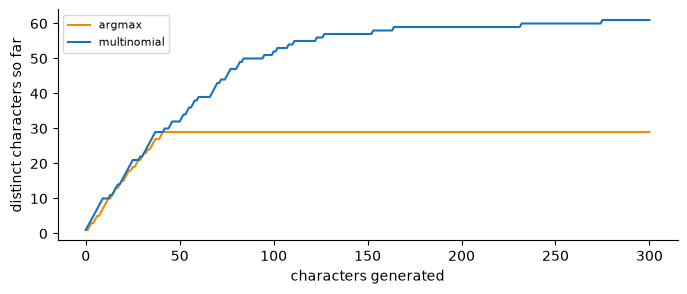

In [51]:
# Why sample instead of taking the argmax? Greedy decoding against sampling, same context.
with torch.no_grad():
    greedy = context
    for _ in range(300):
        logits, _ = model(greedy[:, -block_size:])
        greedy = torch.cat((greedy, logits[:, -1, :].argmax(dim=-1, keepdim=True)), dim=1)
greedy_text = decode(greedy[0].tolist())
tail = greedy_text[100:]
cycle = next((size for size in range(1, len(tail)) if tail[size:] == tail[:-size]), None)
print(f'Greedy start: {greedy_text[:80]!r}')
print(f'Greedy: {len(set(greedy_text))} distinct characters, its tail repeats every {cycle}')
print(f'Sampling: {len(set(untrained_text[:301]))} distinct characters over the same length')

with torch.no_grad():
    probs = F.softmax(model(xb)[0], dim=-1)
entropy = -(probs * torch.log(probs)).sum(dim=-1).mean()
print(f'Next-character distribution on xb: mean entropy {entropy:.2f}, '
      f'ln({vocab_size}) = {math.log(vocab_size):.2f}, '
      f'mean maximum probability {probs.max(dim=-1).values.mean():.3f}')

fig, ax = plt.subplots(figsize=(8, 3))
for name, sample, color in (('argmax', greedy_text, '#f08c00'),
                            ('multinomial', untrained_text[:301], '#1971c2')):
    seen = [len(set(sample[:i + 1])) for i in range(len(sample))]
    ax.plot(range(len(sample)), seen, color=color, label=name)
ax.set_xlabel('characters generated')
ax.set_ylabel('distinct characters so far')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In this untrained model, greedy decoding enters a repeated `J` cycle and uses 29 distinct characters, compared with 61 in the sampled prefix. This supports sampling for variety in the example. It does not guarantee coherent text or imply that every greedy run must loop.

On `xb`, mean entropy is 4.01 and mean maximum probability is 0.052. These are averages over batch positions, so they do not describe every distribution along the greedy trajectory. I next compare aggregate character shares with the corpus before using the same diagnostic after training.


' ': 1.15% of the sample, 15.23% of the corpus
'\n': 1.20% of the sample, 3.59% of the corpus
Uniform share over 65 characters: 1.54%


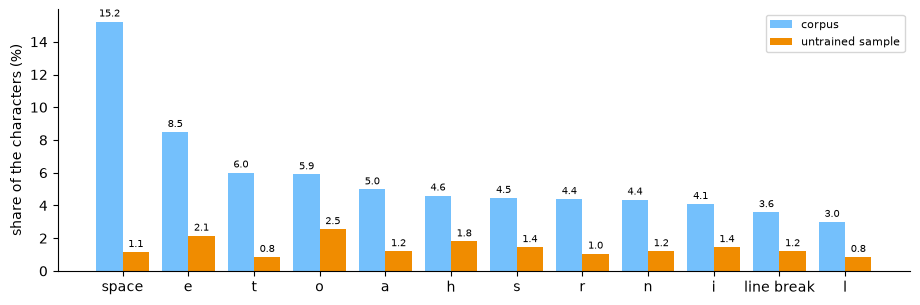

In [52]:
# Does the untrained sample look like the corpus? Shares of the 12 most frequent characters.
from collections import Counter

corpus_counts, sample_counts = Counter(text), Counter(untrained_text)
top = [ch for ch, _ in corpus_counts.most_common(12)]
corpus_share = [100 * corpus_counts[ch] / len(text) for ch in top]
sample_share = [100 * sample_counts[ch] / len(untrained_text) for ch in top]
for ch in (' ', '\n'):
    print(f'{ch!r}: {100 * sample_counts[ch] / len(untrained_text):.2f}% of the sample, '
          f'{100 * corpus_counts[ch] / len(text):.2f}% of the corpus')
print(f'Uniform share over {vocab_size} characters: {100 / vocab_size:.2f}%')

fig, ax = plt.subplots(figsize=(11, 3.4))
positions = torch.arange(len(top))
for offset, shares, name, color in ((-0.2, corpus_share, 'corpus', '#74c0fc'),
                                     (0.2, sample_share, 'untrained sample', '#f08c00')):
    bars = ax.bar(positions + offset, shares, 0.4, color=color, label=name)
    ax.bar_label(bars, labels=[f'{share:.1f}' for share in shares], padding=2, fontsize=7)
ax.set_xticks(positions, [{' ': 'space', '\n': 'line break'}.get(ch, ch) for ch in top])
ax.set_ylabel('share of the characters (%)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The untrained sample has 1.15% spaces and 1.20% line breaks, compared with 15.23% and 3.59% in the full corpus. Its aggregate character shares are closer to the uniform share of 1.54%. That pattern does not make each conditional prediction uniform.


> *My conclusion:*
>
> Generation respects the context limit and produces a baseline for the later sample. The cropping check explains its input limit, while the decoding comparison shows one consequence of choosing the most probable character repeatedly.
>
> My answers to the two questions of this step:
>
> 1. `no_grad` avoids storing a backward graph that generation does not use. It does not switch dropout off or apply updates.
> 2. Multinomial sampling follows the predicted distribution and gave more variety here than greedy decoding. Readability still needs separate inspection.


## 7. Evaluate

The initial batch losses vary, so a single batch could obscure a change in the model. I average random batches while keeping the weights fixed. I then test mode handling, repeated-estimate variability and the difference from a deterministic tiled reference.


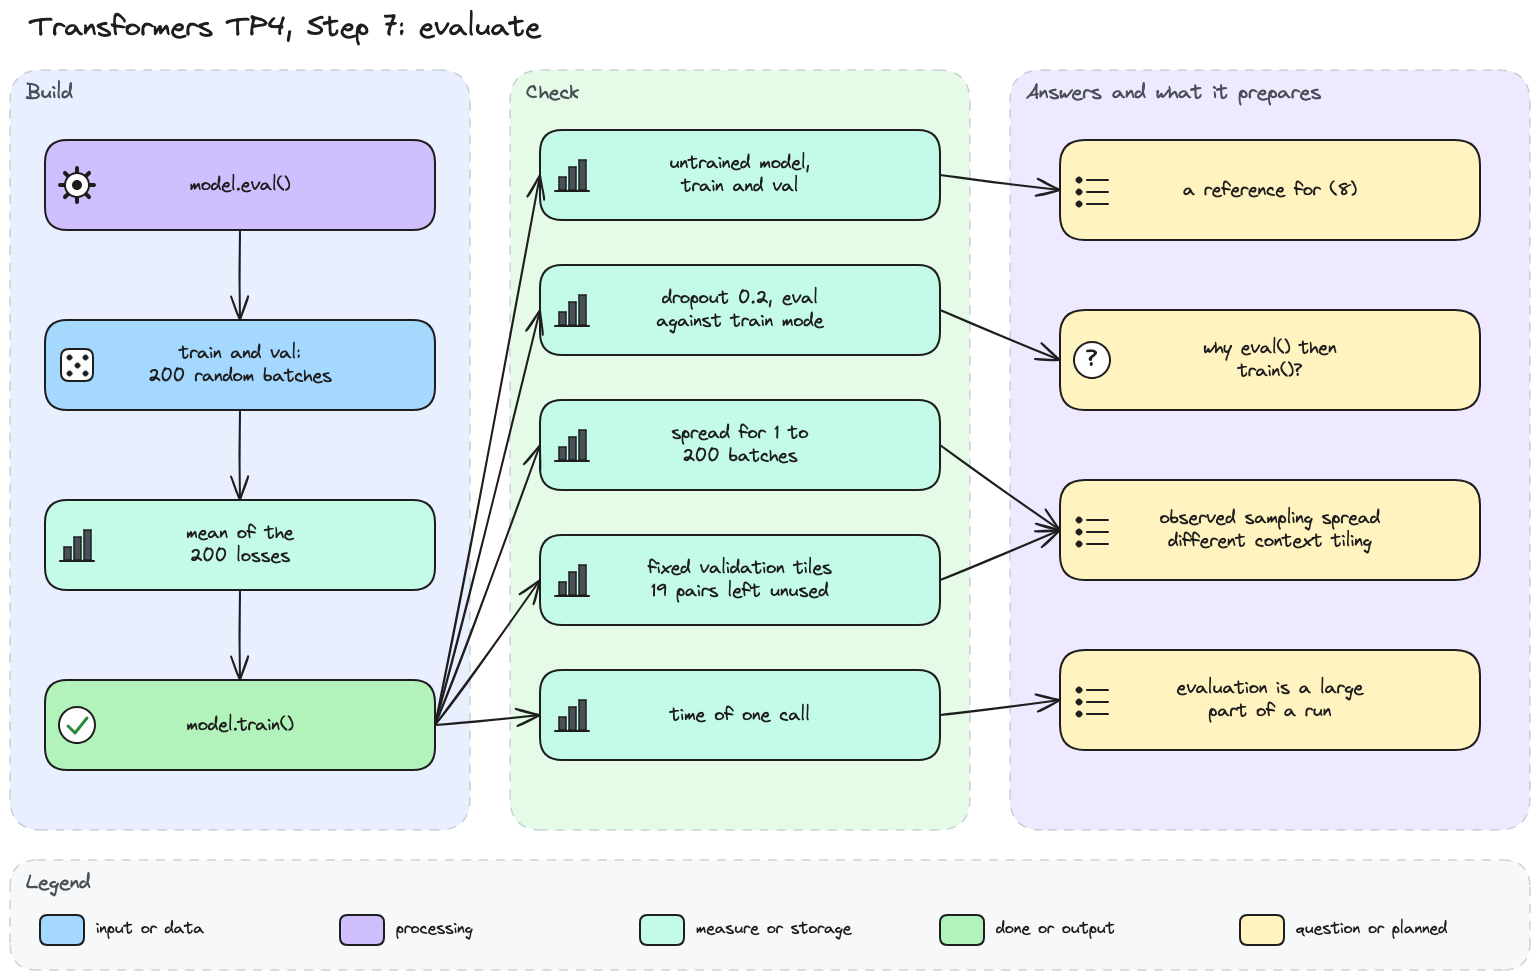

In [53]:
# Step 7 diagram: the provided estimate_loss, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp4_step7.png', width=900))

In [54]:
# The provided evaluation: the mean loss over eval_iters batches of each split, in eval mode.
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

`estimate_loss` measures both splits in evaluation mode without building backward graphs. It always finishes in training mode, even if the incoming mode was evaluation. Its random batch draws advance the same generator used by training, so changing evaluation frequency would also change later training batches.


In [55]:
# The untrained model, measured the way the training loop of section 8 will measure it.
torch.manual_seed(RANDOM_STATE)
print(f'Before the call: model.training {model.training}')
losses = estimate_loss()
print(f'train {losses["train"]:.4f}, val {losses["val"]:.4f}, '
      f'model.training after the call {model.training}')

Before the call: model.training True
train 4.4137, val 4.4041, model.training after the call True


This call gives 4.4137 on training data and 4.4041 on validation, with training mode restored afterward. Those levels agree with the earlier initial-loss measurements. Section 8 resets the seed differently, so its first sampled estimates need not be identical.

I next keep the input and copied weights fixed while switching dropout modes. Repeating the same batch separates randomness inside the model from randomness in batch selection.


In [56]:
# Why model.eval() then model.train()? A copy of the model with dropout 0.2, in both modes.
print(f'Dropout modules in the model: {sum(isinstance(m, nn.Dropout) for m in model.modules())}')
noisy_model = copy.deepcopy(model)
for module in noisy_model.modules():
    if isinstance(module, nn.Dropout):
        module.p = 0.2
with torch.no_grad():
    reference = model(xb, yb)[1].item()
    for mode in ('train', 'eval'):
        noisy_model.train(mode == 'train')
        repeats = [noisy_model(xb, yb)[1].item() for _ in range(5)]
        print(f'{mode} mode, the same batch 5 times: {[round(value, 4) for value in repeats]}')
print(f'The model without dropout on the same batch: {reference:.4f}')

Dropout modules in the model: 24
train mode, the same batch 5 times: [4.3952, 4.3894, 4.3848, 4.3798, 4.3884]
eval mode, the same batch 5 times: [4.3903, 4.3903, 4.3903, 4.3903, 4.3903]
The model without dropout on the same batch: 4.3903


The model has 24 dropout modules across attention weights, projections and MLP outputs. With probability 0.2 in training mode, five passes on the same batch range from 4.3798 to 4.3952. In evaluation mode, all five give 4.3903.

This isolates dropout's effect on the measurement. Both training-split and validation-split estimates use evaluation mode, whereas optimisation uses training mode. I next vary the number of sampled batches to measure the remaining sampling variation.


eval_iters = 1: val estimates from 4.3583 to 4.4703, std 0.0275
eval_iters = 10: val estimates from 4.3936 to 4.4156, std 0.0062
eval_iters = 50: val estimates from 4.3985 to 4.4096, std 0.0026
eval_iters = 200: val estimates from 4.3989 to 4.4065, std 0.0020


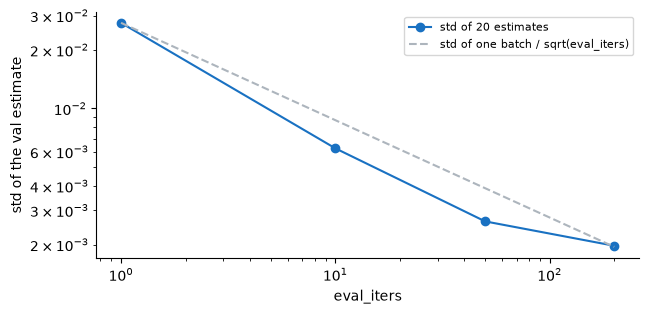

In [57]:
# How many batches does the estimate need? The spread of 20 repeated estimates per eval_iters.
ITERS = [1, 10, 50, 200]
saved_eval_iters = eval_iters
spreads = []
torch.manual_seed(RANDOM_STATE)
try:
    for eval_iters in ITERS:  # estimate_loss reads this global
        estimates = torch.tensor([estimate_loss()['val'].item() for _ in range(20)])
        spreads.append(estimates.std().item())
        print(f'eval_iters = {eval_iters}: val estimates from {estimates.min():.4f} '
              f'to {estimates.max():.4f}, std {spreads[-1]:.4f}')
finally:
    eval_iters = saved_eval_iters

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ITERS, spreads, marker='o', color='#1971c2', label='std of 20 estimates')
ax.plot(ITERS, [spreads[0] / math.sqrt(n) for n in ITERS], linestyle='--', color='#adb5bd',
        label='std of one batch / sqrt(eval_iters)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('eval_iters')
ax.set_ylabel('std of the val estimate')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Over 20 repeated estimates, the observed standard deviation falls from 0.0275 with one batch to 0.0020 with 200. This is the sampling spread for this fixed untrained model, not a confidence interval or a bound for every checkpoint.

The square-root reference assumes independent batch draws with finite variance, conditional on the fixed corpus and model. Positions inside a batch can still share context. I next score fixed tiles to see how a different selection of prediction contexts compares.


In [58]:
# Compare random-window evaluation with a fixed, non-overlapping tiling of validation.
windows = (len(val_data) - 1) // block_size
inputs = val_data[:windows * block_size].view(windows, block_size).to(device)
targets = val_data[1:windows * block_size + 1].view(windows, block_size).to(device)
total = 0.0
model.eval()
with torch.no_grad():
    for start in range(0, windows, 256):
        _, loss = model(inputs[start:start + 256], targets[start:start + 256])
        total += loss.item() * inputs[start:start + 256].numel()
model.train()
full_val = total / (windows * block_size)
print(f'Adjacent pairs omitted at the end: {len(val_data) - 1 - windows * block_size}')
print(f'{windows:,} windows of {block_size} characters, {windows * block_size:,} predictions')
print(f'Loss on fixed validation tiles: {full_val:.4f}, '
      f'estimate from 200 batches: {losses["val"]:.4f}')

Adjacent pairs omitted at the end: 19
3,485 windows of 32 characters, 111,520 predictions
Loss on fixed validation tiles: 4.4013, estimate from 200 batches: 4.4041


The tiled calculation scores 111,520 positions in 3,485 non-overlapping windows and leaves 19 final adjacent pairs unused. Its loss is 4.4013, compared with 4.4041 from random batches.

Each tile fixes where context restarts, whereas random windows assign different prefixes to corpus positions. The close scores are reassuring for this model, but these procedures do not evaluate exactly the same collection of predictions. I keep the random estimator for the existing runs and measure its local cost next.


One estimate_loss call: 1.52 s, one training step: 13.1 ms
evaluation, 51 calls: about 78 s per full run
training, 5,000 steps: about 66 s per full run


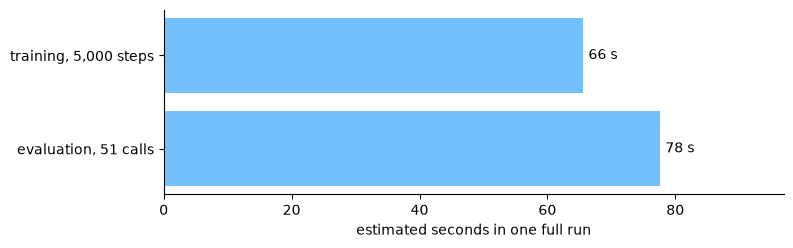

In [59]:
# What does evaluation cost in a full run? One estimate_loss call against one training step.
import time

torch.manual_seed(RANDOM_STATE)
call_time = min(timeit.repeat(estimate_loss, number=1, repeat=3))
scratch = copy.deepcopy(model)  # a copy, so the real weights stay untouched
optimizer = torch.optim.AdamW(scratch.parameters(), lr=learning_rate)
start = time.perf_counter()
for _ in range(20):
    xs, ys = get_batch('train')
    _, loss = scratch(xs, ys)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
step_time = (time.perf_counter() - start) / 20

run_cost = {f'evaluation, {evaluations} calls': evaluations * call_time,
            f'training, {max_iters:,} steps': max_iters * step_time}
print(f'One estimate_loss call: {call_time:.2f} s, one training step: {1000 * step_time:.1f} ms')
for name, seconds in run_cost.items():
    print(f'{name}: about {seconds:.0f} s per full run')

fig, ax = plt.subplots(figsize=(8, 2.4))
bars = ax.barh(list(run_cost), list(run_cost.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{seconds:.0f} s' for seconds in run_cost.values()], padding=4)
ax.set_xlim(0, max(run_cost.values()) * 1.25)
ax.set_xlabel('estimated seconds in one full run')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The displayed timings compare the fastest of three evaluation calls with the average of 20 training steps on a copy. Multiplying by 51 calls and 5,000 steps estimates the two contributions to a full run. These local measurements guide the budget without promising a fixed duration.


> *My conclusion:*
>
> Averaging batches reduced the observed sampling spread on the fixed untrained model. The tiled reference gives a nearby score under a different context assignment. I keep the evaluation schedule fixed because its random draws also affect later training batches.
>
> My answer to the first question of this step:
>
> - Evaluation mode disables dropout for both split estimates, and training mode enables it for optimisation. `no_grad` separately disables graph construction.
>
> The next section answers the second question with training and validation curves that move in opposite directions.


## 8. Train

I have checked the forward calculation, but those checks do not show whether optimisation reduces the loss. I first separate gradient calculation from an update, then test 200 steps on a model copy. Only after that check do I train for 5,000 steps.


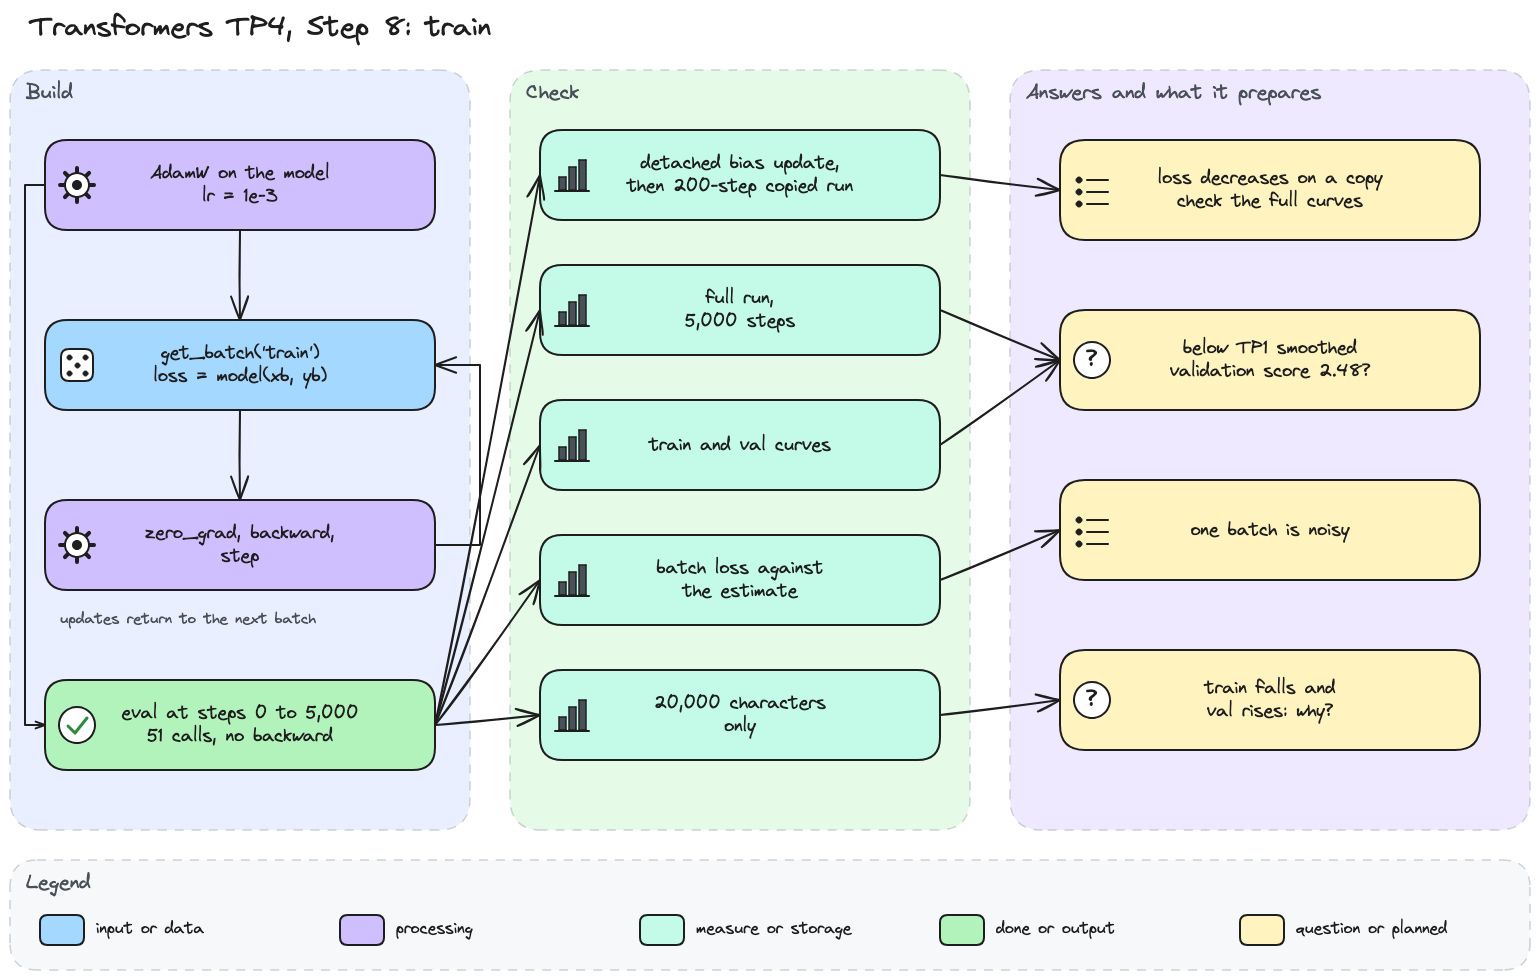

In [60]:
# Step 8 diagram: the AdamW loop, the full run, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp4_step8.png', width=900))

In [61]:
# Tools: the existing training loop on the global model, keeping the estimates and batch losses.
def train_model(steps: int) -> dict:
    """The existing loop on the global model: AdamW, and estimate_loss every eval_interval steps."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = {'step': [], 'train': [], 'val': [], 'batch': []}
    for iteration in range(steps + 1):  # the extra pass only evaluates the final weights
        if iteration % eval_interval == 0 or iteration == steps:
            losses = estimate_loss()
            history['step'].append(iteration)
            history['train'].append(losses['train'].item())
            history['val'].append(losses['val'].item())
            if iteration % 500 == 0 or iteration == steps:
                print(f'step {iteration}: train {losses["train"]:.4f}, val {losses["val"]:.4f}')
        if iteration == steps:
            break
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        history['batch'].append(loss.item())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return history

`loss.backward()` computes gradients and `optimizer.step()` uses them to update parameters. AdamW also uses adaptive moments and weight decay, so its learning rate alone does not specify the update size.

I first isolate the output bias for one existing prediction on a detached copy. Comparing its analytical gradient and first AdamW update with PyTorch makes the distinction visible without changing the model.


In [62]:
# Separate a gradient calculation from a first AdamW update on a detached bias copy.
demo_bias_before = model.lm_head.bias.detach().clone()
demo_bias = demo_bias_before.clone().requires_grad_()
demo_fixed_logits = flat_logits[35].detach() - demo_bias_before
demo_logits = demo_fixed_logits + demo_bias
demo_label = yb.reshape(-1)[35].detach()
demo_ce = F.cross_entropy(demo_logits[None], demo_label[None])
demo_grad, = torch.autograd.grad(demo_ce, demo_bias)
demo_expected_grad = F.softmax(demo_logits.detach(), dim=-1)
demo_expected_grad = demo_expected_grad - F.one_hot(demo_label, vocab_size)
assert torch.allclose(demo_grad, demo_expected_grad, atol=1e-7, rtol=1e-5)
assert torch.equal(demo_bias.detach(), demo_bias_before)
demo_optimizer = torch.optim.AdamW([demo_bias], lr=learning_rate)
demo_options = demo_optimizer.param_groups[0]
demo_beta1, demo_beta2 = demo_options['betas']
demo_m = (1 - demo_beta1) * demo_grad
demo_v = (1 - demo_beta2) * demo_grad.square()
demo_m_hat = demo_m / (1 - demo_beta1)
demo_v_hat = demo_v / (1 - demo_beta2)
demo_expected_bias = demo_bias_before * (1 - learning_rate * demo_options['weight_decay'])
demo_expected_bias -= learning_rate * demo_m_hat / (demo_v_hat.sqrt() + demo_options['eps'])
demo_bias.grad = demo_grad.clone()
demo_optimizer.step()
assert torch.allclose(demo_bias.detach(), demo_expected_bias, atol=1e-7, rtol=1e-5)
print(f'AdamW lr {learning_rate}, betas {demo_options["betas"]}, '
      f'eps {demo_options["eps"]}, weight decay {demo_options["weight_decay"]}')
for demo_j in (demo_label.item(), (demo_label.item() + 1) % vocab_size):
    print(f'Character {itos[demo_j]!r}: gradient {demo_grad[demo_j]:.6f}, '
          f'bias {demo_bias_before[demo_j]:.6f} -> {demo_bias[demo_j].detach():.6f}, '
          f'change {(demo_bias[demo_j].detach() - demo_bias_before[demo_j]):.6f}')
print('Gradient and first update agree with PyTorch on the detached copy.')


AdamW lr 0.001, betas (0.9, 0.999), eps 1e-08, weight decay 0.01
Character ' ': gradient -0.992061, bias -0.091985 -> -0.090984, change 0.001001
Character '!': gradient 0.026868, bias 0.053298 -> 0.052297, change -0.001001
Gradient and first update agree with PyTorch on the detached copy.


For this prediction, the target's negative gradient favours increasing its logit, while other logits have positive gradients. Calculating those gradients leaves the bias unchanged until the separate update. AdamW then combines adaptive moments and weight decay, as the copied first step shows.

Real training backpropagates through the full model and reuses optimiser state across steps. I next test that loop on a copy, keeping the original initial weights for the full run.


In [63]:
# A very short test first, on a copy, so the real model starts the full run untouched.
real_model = model
model = copy.deepcopy(real_model)  # train_model and estimate_loss read the global name
try:
    torch.manual_seed(RANDOM_STATE)
    start = time.perf_counter()
    test_history = train_model(200)
    print(f'200 steps in {time.perf_counter() - start:.0f} s, estimates at steps '
          f'{test_history["step"]}')
finally:
    model = real_model
with torch.no_grad():
    print(f'Real model on xb after the test: loss {model(xb, yb)[1].item():.4f}')

step 0: train 4.4137, val 4.4041
step 200: train 2.4920, val 2.4979
200 steps in 7 s, estimates at steps [0, 100, 200]
Real model on xb after the test: loss 4.3903


After 200 steps on the copy, training loss falls from 4.4137 to 2.4920 and validation loss from 4.4041 to 2.4979. This is a useful optimisation check, although loss reduction alone cannot exclude every implementation error. The original model still scores 4.3903 on `xb`, so I can start the full run from the intended weights.


In [64]:
# The full run: 5,000 AdamW steps on the model built in section 4.
torch.manual_seed(1337)
start = time.perf_counter()
history = train_model(max_iters)
print(f'{max_iters:,} steps in about {time.perf_counter() - start:.0f} s')

step 0: train 4.4069, val 4.4009
step 500: train 2.2776, val 2.2868
step 1000: train 2.0602, val 2.1129
step 1500: train 1.9428, val 2.0146
step 2000: train 1.8559, val 1.9655
step 2500: train 1.8007, val 1.9110
step 3000: train 1.7764, val 1.9085
step 3500: train 1.7232, val 1.8665
step 4000: train 1.7117, val 1.8534
step 4500: train 1.6809, val 1.8407
step 5000: train 1.6730, val 1.8280
5,000 steps in about 139 s


After 500 steps, estimated training and validation losses are 2.2776 and 2.2868. They reach 1.6730 and 1.8280 after 5,000 steps. I now inspect the recorded checkpoints to distinguish final performance, the lowest sampled validation score and the gap between splits.


TP1 corpus-fitted reference 2.45, smoothed training-count model on validation 2.48
Final: train 1.6730, val 1.8280
Gap val - train at steps 0, 1,000, 2,500 and 5,000: -0.006, 0.053, 0.110, 0.155
Lowest val 1.8190 at step 4,900, first val below 2.48 at step 300


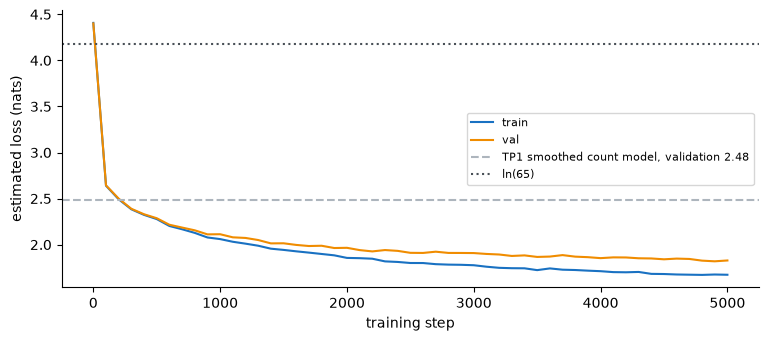

In [65]:
# Did the model beat my TP1 bigram, and do train and val stay close? The two curves.
TP1_FLOOR = 2.45  # legacy name for the corpus-fitted empirical TP1 reference
TP1_VALIDATION_REFERENCE = 2.48  # TP1 training counts, add-one smoothing, validation pairs
assert len(history["step"]) == evaluations
print(f'TP1 corpus-fitted reference {TP1_FLOOR:.2f}, '
      f'smoothed training-count model on validation {TP1_VALIDATION_REFERENCE:.2f}')
gaps = {step: val - train for step, train, val
        in zip(history['step'], history['train'], history['val'])}
best = min(range(len(history['val'])), key=history['val'].__getitem__)
first_below = next(step for step, val in zip(history['step'], history['val'])
                   if val < TP1_VALIDATION_REFERENCE)
print(f'Final: train {history["train"][-1]:.4f}, val {history["val"][-1]:.4f}')
print('Gap val - train at steps 0, 1,000, 2,500 and 5,000: '
      + ', '.join(f'{gaps[step]:.3f}' for step in (0, 1000, 2500, max_iters)))
print(f'Lowest val {history["val"][best]:.4f} at step {history["step"][best]:,}, '
      f'first val below {TP1_VALIDATION_REFERENCE} at step {first_below}')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(history['step'], history['train'], color='#1971c2', label='train')
ax.plot(history['step'], history['val'], color='#f08c00', label='val')
ax.axhline(TP1_VALIDATION_REFERENCE, linestyle='--', color='#adb5bd',
           label='TP1 smoothed count model, validation 2.48')
ax.axhline(math.log(vocab_size), linestyle=':', color='#495057', label='ln(65)')
ax.set_xlabel('training step')
ax.set_ylabel('estimated loss (nats)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The final validation loss is 1.8280, below both my original 2.45 hypothesis and TP1's smoothed validation reference of 2.48. This supports the numerical prediction, but context, parameter count and training all changed from TP1. I cannot assign the gain to attention alone.

The lowest observed validation score is 1.8190 at step 4,900, while the retained model is the final step 5,000 model. Intermediate weights were not saved. The gap grows from -0.006 to 0.155, qualifying my hypothesis of close curves even though validation improves overall.

I next compare the raw batch losses with the averaged estimates. This checks how much apparent movement comes from the chosen batch while optimisation continues.


Batch losses over the last 1,000 steps: mean 1.688, std 0.076, from 1.439 to 1.939
Train estimate at the end: 1.673


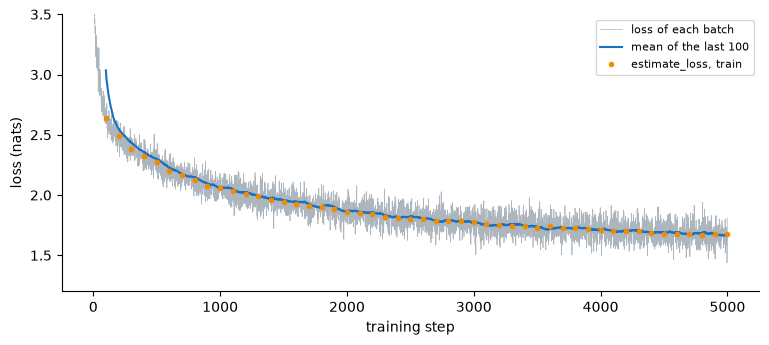

In [66]:
# How noisy is one training batch? The 5,000 batch losses against the estimates.
batch_losses = torch.tensor(history['batch'])
moving = batch_losses.unfold(0, 100, 1).mean(dim=1)  # mean of each window of 100 steps
last = batch_losses[-1000:]
print(f'Batch losses over the last 1,000 steps: mean {last.mean():.3f}, std {last.std():.3f}, '
      f'from {last.min():.3f} to {last.max():.3f}')
print(f'Train estimate at the end: {history["train"][-1]:.3f}')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(batch_losses, color='#adb5bd', linewidth=0.5, label='loss of each batch')
ax.plot(range(99, len(batch_losses)), moving, color='#1971c2', label='mean of the last 100')
ax.plot(history['step'], history['train'], 'o', markersize=3, color='#f08c00',
        label='estimate_loss, train')
ax.set_ylim(1.2, 3.5)
ax.set_xlabel('training step')
ax.set_ylabel('loss (nats)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The last 1,000 batch losses average 1.688, with standard deviation 0.076 and range 1.439 to 1.939. These losses come from changing model states and sampled batches, so their spread mixes training progress and sampling variation. The rolling 100-step mean is a separate visual smoothing operation.

The final training estimate is 1.673 on the final model. I next restrict training to a corpus prefix to examine a clearer case of divergence between training and validation losses.


step 0: train 4.4042, val 4.4020
step 500: train 2.0949, val 2.4478
step 1000: train 1.7656, val 2.4204
step 1500: train 1.5388, val 2.5045
step 2000: train 1.3106, val 2.6664
step 2500: train 1.1435, val 2.8602
step 3000: train 0.9951, val 3.0660
Lowest val 2.420 at step 1,000


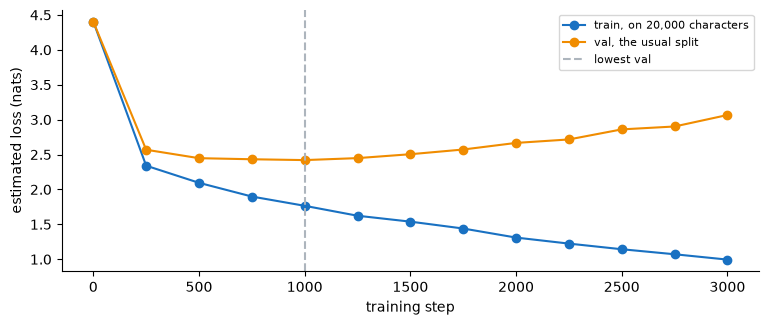

In [67]:
# What if the model sees too little text? A fresh model trained on 20,000 characters only.
saved = (model, train_data, eval_interval, eval_iters)
try:
    torch.manual_seed(1337)
    model = BigramLanguageModel().to(device)
    # get_batch and estimate_loss read these globals
    train_data, eval_interval, eval_iters = saved[1][:20_000], 250, 50
    small_history = train_model(3000)
finally:
    model, train_data, eval_interval, eval_iters = saved
lowest = min(range(len(small_history['val'])), key=small_history['val'].__getitem__)
print(f'Lowest val {small_history["val"][lowest]:.3f} at step {small_history["step"][lowest]:,}')

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(small_history['step'], small_history['train'], marker='o', color='#1971c2',
        label='train, on 20,000 characters')
ax.plot(small_history['step'], small_history['val'], marker='o', color='#f08c00',
        label='val, the usual split')
ax.axvline(small_history['step'][lowest], linestyle='--', color='#adb5bd',
           label='lowest val')
ax.set_xlabel('training step')
ax.set_ylabel('estimated loss (nats)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

On the 20,000-character prefix, training loss reaches 0.9951 at step 3,000 while validation rises to 3.0660 after its observed minimum of 2.420 at step 1,000. This is evidence of overfitting in that run. It does not establish literal memorisation, and the minimum's weights were not retained.

This comparison also changes the text distribution, step budget and evaluation settings. I use it to recognise the curve pattern, rather than estimate an isolated effect of corpus size.


> *My conclusion:*
>
> The copied run checked that optimisation lowered the loss before the full run. The final model reaches 1.8280 on validation, below TP1's 2.48 smoothed reference, with a train/validation gap of 0.155. My numerical improvement hypothesis holds, while the explanation needs the capacity and training qualifications.
>
> My answer to the second evaluation question:
>
> - Falling training loss alongside rising validation loss indicates overfitting in the observed run. The corpus-prefix experiment shows that pattern after its lowest recorded validation score.


## 9. Train, generate and experiment

I first compare samples from the same starting character and sampling seed before and after training. I then compare context length, head count and dropout using fresh models. Equal step counts do not guarantee equal processing budgets or matched random batches.


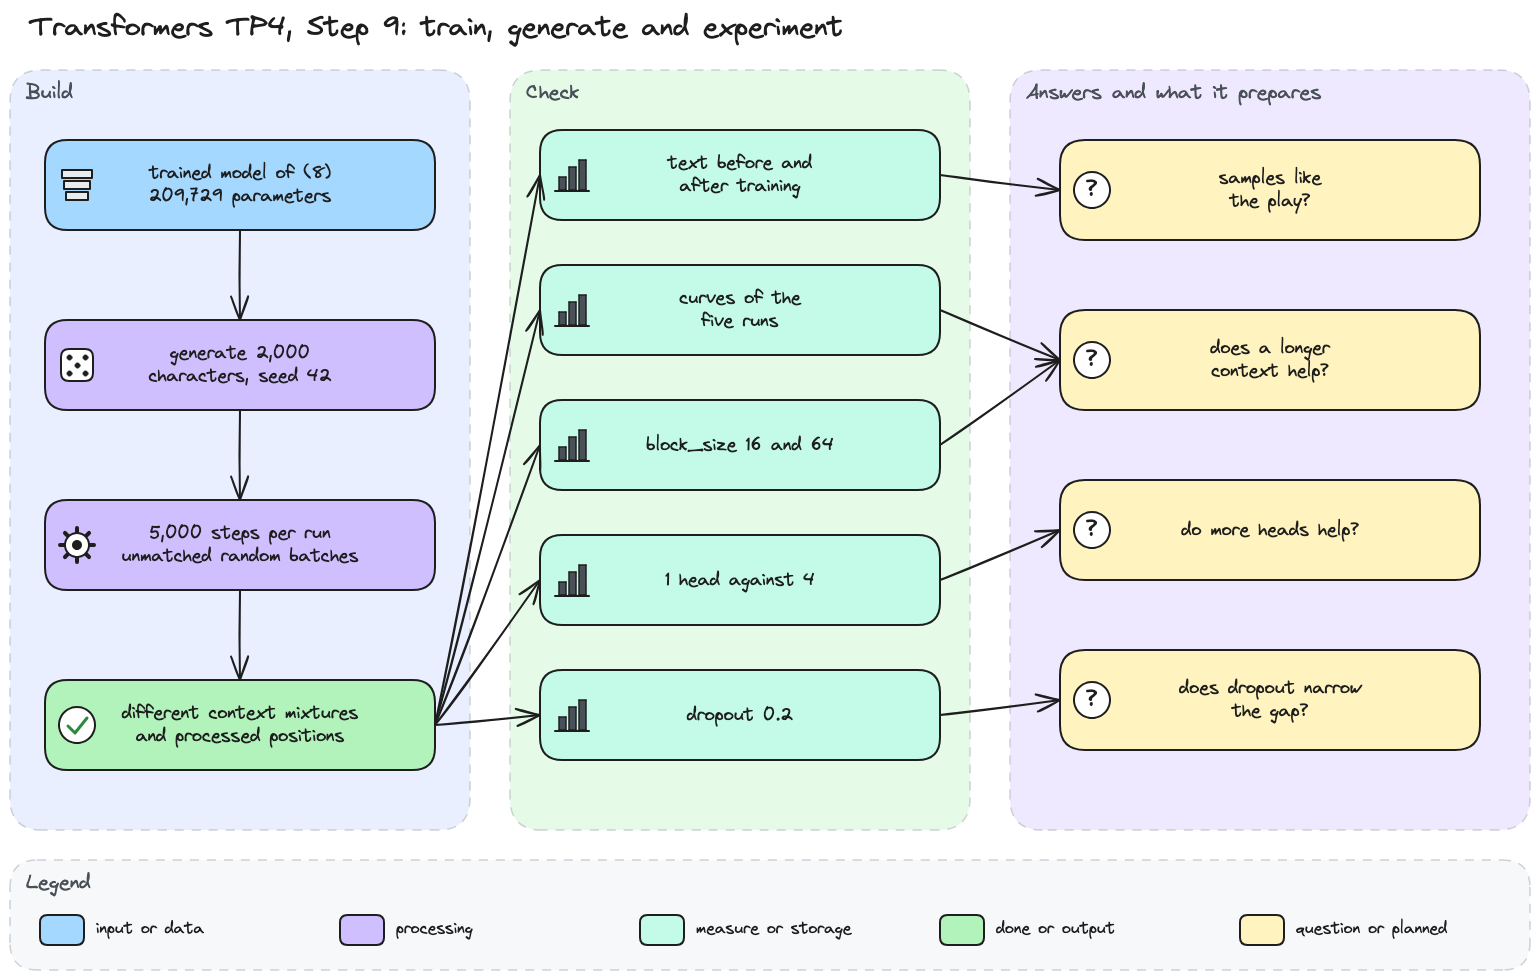

In [68]:
# Step 9 diagram: the trained model, its text, and the four experiments.
display(Image(filename='diagrams/transformers/tp4_step9.png', width=900))

In [69]:
# The existing step 9 on my trained model: its size, then 2,000 characters from a line break.
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M parameters')
torch.manual_seed(RANDOM_STATE)  # the seed of the untrained sample of section 6
context = torch.zeros((1, 1), dtype=torch.long, device=device)
result = model.generate(context, max_new_tokens=2000)
trained_text = decode(result[0].tolist())
print(trained_text)

0.209729 M parameters

Mystland save is not distrear a stongetnes of the Vole?

PETRUCESTER:
Noqure of the mair kulgnt here's to to beut.

AUTOO:
Nor chear, Bunted fleach, are ought for not breaten in the stantiunior arms;
But hoped thy thus coome; thoughnelo,
For any hound beform and with course?
Doth may I spoked and breath thoughts,
DUCHESore on pass poot cleasten,
So his hold stay she
Bringthe-hour on of I do, yet is
What thangure thear to moraven
On to liburiliged her and grievere in
In not in jury thoughter.

MARINCE:
Sir, and thrige love, the lord; master'd were shat dimsmoln hoolg: one,
Fir, thus sea consilt go droate?

LEONTES:
As this to hust,
Spleen'd weill noble forgings, fanathio,
A epear your thut breamoudget her
shall busiace werl: pranded I his friend were the refly when! That
Warwick young tears, this doop heaven honours. Could it, mastled the foulthy withoury.

VING MARD I'll stonce, thoughtour Duke's thesem, I well there, and where her first do livery hath
The forget

The trained sample has recognisable speaker-style lines and speech-like punctuation. It also contains invented fragments such as `stantiunior` and `thoughnelo`, so the layout improvement does not establish coherent English. I next count simple features to support that reading of this sample.


untrained: 302 extracted word occurrences, 4.64% of them in the corpus, 0 speaker-style lines, 0 corpus name matches
trained: 362 extracted word occurrences, 68.23% of them in the corpus, 10 speaker-style lines, 2 corpus name matches
corpus: spaces 15.23%, line breaks 3.59%
untrained: spaces 1.15%, line breaks 1.20%
trained: spaces 15.54%, line breaks 3.00%


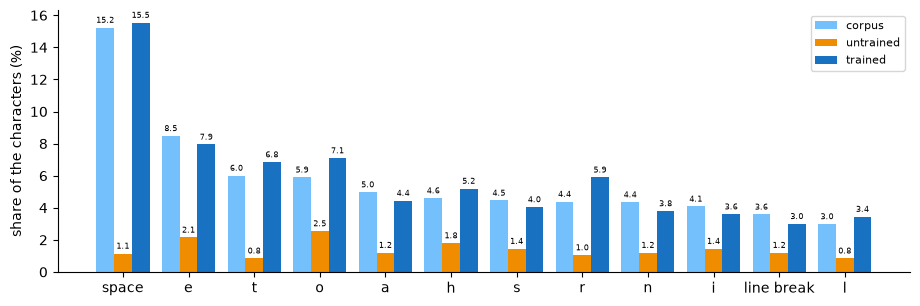

In [70]:
# Does training make the text look like the play? Words, speaker lines and character shares.
import re

WORD = r"[A-Za-z']+"
SPEAKER = r"^([A-Z][A-Za-z ]+):$"  # a line that holds only a name and a colon
corpus_words = set(re.findall(WORD, text))
speakers = set(re.findall(SPEAKER, text, flags=re.M))
samples = {'untrained': untrained_text, 'trained': trained_text}
for name, sample in samples.items():
    words = re.findall(WORD, sample)
    names = re.findall(SPEAKER, sample, flags=re.M)
    print(f'{name}: {len(words)} extracted word occurrences, '
          f'{100 * sum(word in corpus_words for word in words) / len(words):.2f}% of them in the '
          f'corpus, {len(names)} speaker-style lines, '
          f'{sum(n in speakers for n in names)} corpus name matches')
for name, sample in {'corpus': text, **samples}.items():
    print(f'{name}: spaces {100 * sample.count(" ") / len(sample):.2f}%, '
          f'line breaks {100 * sample.count(chr(10)) / len(sample):.2f}%')

fig, ax = plt.subplots(figsize=(11, 3.4))
for offset, (name, sample), color in zip((-0.27, 0, 0.27), {'corpus': text, **samples}.items(),
                                          ('#74c0fc', '#f08c00', '#1971c2')):
    shares = [100 * sample.count(ch) / len(sample) for ch in top]
    bars = ax.bar(positions + offset, shares, 0.27, color=color, label=name)
    ax.bar_label(bars, labels=[f'{share:.1f}' for share in shares], padding=2, fontsize=6)
ax.set_xticks(positions, [{' ': 'space', '\n': 'line break'}.get(ch, ch) for ch in top])
ax.set_ylabel('share of the characters (%)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Corpus matches rise from 4.64% of 302 extracted word occurrences to 68.23% of 362. The trained sample has 10 speaker-style lines, with two occurrences matching corpus speaker names. These case-sensitive checks use the full corpus, including validation text, so they are descriptive references rather than independent language-quality tests.

Spaces reach 15.54% and line breaks 3.00%, near the corpus shares of 15.23% and 3.59%. These measurements support the layout part of my hypothesis. They do not test grammar or meaning.

For the variants, `run_with` seeds before constructing the model, whereas the baseline seeds again after construction. Shape changes and dropout also consume randomness differently, so the runs do not share a matched batch sequence. This limits how confidently I can attribute each score difference to the setting being changed.


In [71]:
# Tools: train a fresh model with some constants changed, then put every constant back.
import contextlib
import io


def run_with(settings: dict) -> dict:
    """Train a fresh seeded model for max_iters steps under settings, then restore the globals."""
    saved = {name: globals()[name] for name in ('model', *settings)}
    try:
        globals().update(settings)  # the classes, get_batch and generate read these globals
        torch.manual_seed(1337)
        globals()['model'] = BigramLanguageModel().to(device)
        start = time.perf_counter()
        with contextlib.redirect_stdout(io.StringIO()):  # the final summary is enough here
            run_history = train_model(max_iters)
        seconds = time.perf_counter() - start
        torch.manual_seed(RANDOM_STATE)
        sample = decode(model.generate(context, max_new_tokens=300)[0].tolist())
        return {'history': run_history, 'seconds': seconds, 'sample': sample,
                'parameters': sum(p.numel() for p in model.parameters())}
    finally:
        globals().update(saved)


def describe(name: str, run: dict) -> str:
    """One line with the final losses, the gap and the size of a run."""
    train, val = run['history']['train'][-1], run['history']['val'][-1]
    return (f'{name}: train {train:.4f}, val {val:.4f}, gap {val - train:.3f}, '
            f'{run["parameters"]:,} parameters')


baseline = {'history': history, 'parameters': sum(p.numel() for p in model.parameters())}

In [72]:
# Does a longer context help? The same training with block_size 16, then 64.
context_runs = {size: run_with({'block_size': size}) for size in (16, 64)}
print(describe('block_size 32, section 8', baseline))
for demo_size in (16, 32, 64):
    print(f'Context {demo_size}: {max_iters * batch_size * demo_size:,} target positions, '
          f'mean prefix length {(demo_size + 1) / 2:g} in training and evaluation')
for size, run in context_runs.items():
    print(describe(f'block_size {size}', run) + f', about {run["seconds"]:.0f} s')
    print(f'    sample: {run["sample"][:120]!r}')

block_size 32, section 8: train 1.6730, val 1.8280, gap 0.155, 209,729 parameters
Context 16: 1,280,000 target positions, mean prefix length 8.5 in training and evaluation
Context 32: 2,560,000 target positions, mean prefix length 16.5 in training and evaluation
Context 64: 5,120,000 target positions, mean prefix length 32.5 in training and evaluation
block_size 16: train 1.7574, val 1.9195, gap 0.162, 208,705 parameters, about 121 s
    sample: '\n\nKIDY Clown:\n\nCaunt Claren:\nThat, Sallanty noune of yet all.\n\nKING MARGARETH:\nI knot all thegry heart, that is u\nneveig'
block_size 64: train 1.5871, val 1.7651, gap 0.178, 211,777 parameters, about 242 s
    sample: "\n\nKING LEWICHARD I:\nGod you well speake noble courty, ereal her that\ngreat revoty detial's pleny her,\nTwo look in\nceasit"


Final validation losses are 1.9195, 1.8280 and 1.7651 for contexts 16, 32 and 64. At equal step counts, they process 1.28, 2.56 and 5.12 million target positions. Position-table sizes and subsequent random initialisations also differ.

A longer window changes the mixture of prefix lengths used for both training and evaluation. The lower observed score at 64 therefore cannot isolate the benefit of longer context at equal data exposure. The displayed times are local measurements of these different workloads.


In [73]:
# Do more heads help? One head of 64 channels against the four heads of 16 of section 8.
one_head = run_with({'n_head': 1})
print(describe('4 heads of 16, section 8', baseline))
print(describe('1 head of 64', one_head) + f', about {one_head["seconds"]:.0f} s')
print(f'    sample: {one_head["sample"][:120]!r}')

4 heads of 16, section 8: train 1.6730, val 1.8280, gap 0.155, 209,729 parameters
1 head of 64: train 1.6505, val 1.8180, gap 0.167, 209,729 parameters, about 82 s
    sample: '\n\nKING LIfS\nThat you more consure, So a nobled fear of that heed like the dreath\nWith all kingnly some, that is u\ncerefe'


One head ends at 1.8180 and four heads at 1.8280, with the same 209,729 parameters. The difference is about 0.01 in these separate runs, with no repeated runs to estimate its variability. This gives no demonstrated advantage for more heads and does not establish equivalence between the configurations.

The timing comparison concerns these implementations on this machine. Equal parameter counts do not imply equal execution cost.


In [74]:
# Does dropout narrow the gap? The same training with dropout 0.2.
with_dropout = run_with({'dropout': 0.2})
print(describe('dropout 0.0, section 8', baseline))
print(describe('dropout 0.2', with_dropout) + f', about {with_dropout["seconds"]:.0f} s')
print(f'    sample in training mode, dropout active: {with_dropout["sample"][:120]!r}')

dropout 0.0, section 8: train 1.6730, val 1.8280, gap 0.155, 209,729 parameters
dropout 0.2: train 1.7748, val 1.9056, gap 0.131, 209,729 parameters, about 152 s
    sample in training mode, dropout active: '\nFir Lonentrand my faire word hom pout, are lagpt my jeling the sopuse doid her the upot the curt: do chance crate the d'


Dropout 0.2 reduces the observed gap from 0.155 to 0.131, but validation loss rises from 1.8280 to 1.9056. A smaller gap alone is therefore insufficient evidence of better generalisation. Both split estimates disable dropout, so they remain comparable as evaluation-mode measurements at context 32.

The generated dropout sample retains training mode because `generate` only disables gradients. It includes dropout randomness and cannot serve as an evaluation-mode generation comparison. These runs do not establish whether more training or a smaller corpus would change the dropout result.


block_size 64: val 1.7651
1 head of 64: val 1.8180
baseline of section 8: val 1.8280
dropout 0.2: val 1.9056
block_size 16: val 1.9195


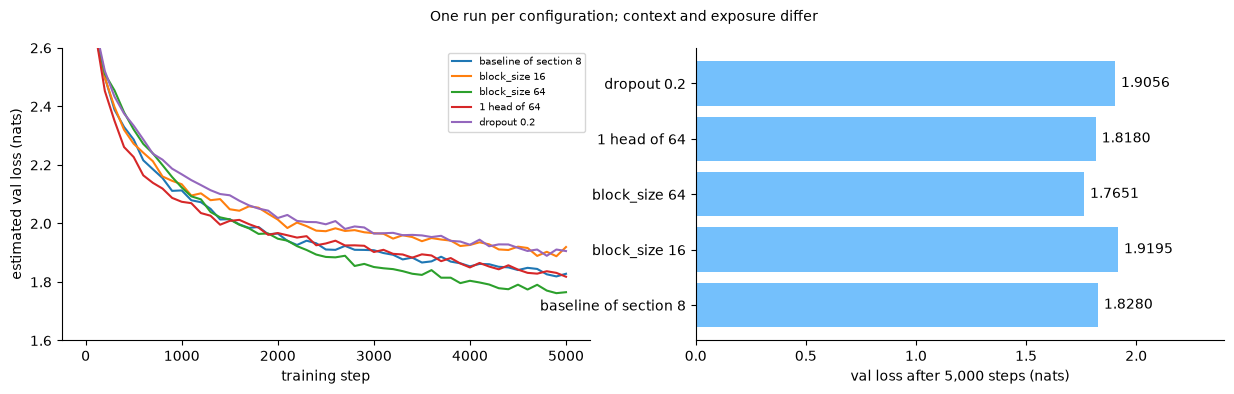

In [75]:
# The five runs side by side: validation curves, then the final validation loss of each.
runs = {'baseline of section 8': baseline,
        'block_size 16': context_runs[16], 'block_size 64': context_runs[64],
        '1 head of 64': one_head, 'dropout 0.2': with_dropout}
final_val = {name: run['history']['val'][-1] for name, run in runs.items()}
best_name = min(final_val, key=final_val.get)
for name, val in sorted(final_val.items(), key=lambda item: item[1]):
    print(f'{name}: val {val:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for name, run in runs.items():
    axes[0].plot(run['history']['step'], run['history']['val'], label=name)
axes[0].set_ylim(1.6, 2.6)
axes[0].set_xlabel('training step')
axes[0].set_ylabel('estimated val loss (nats)')
axes[0].legend(fontsize=7)
bars = axes[1].barh(list(final_val), list(final_val.values()), color='#74c0fc')
axes[1].bar_label(bars, labels=[f'{val:.4f}' for val in final_val.values()], padding=4)
axes[1].set_xlim(0, max(final_val.values()) * 1.25)
axes[1].set_xlabel('val loss after 5,000 steps (nats)')
fig.suptitle('One run per configuration; context and exposure differ', fontsize=10)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

The curves improve overall, with fluctuations between checkpoints. Their final displayed scores describe each configuration's own evaluation protocol, including its context-length mixture. I have reused validation to compare choices and have no separate held-out test result here.

My expectation about longer context matches the ordering of these scores, with the processing-budget qualification. More heads do not produce a lower observed score. One run per configuration leaves both effects uncertain beyond these measurements.


> *My conclusion:*
>
> Training improves the sample's layout and corpus matches, while readable generation remains a separate judgement. The configuration results suggest questions for a more controlled comparison, rather than settle which design is generally best.
>
> My results for the five items of this step:
>
> 1. Corpus word matches rise from 4.64% to 68.23%, and the trained sample has 10 speaker-style lines.
> 2. Baseline losses reach 1.6730 on train and 1.8280 on validation, with fluctuations along the curves.
> 3. Contexts 16, 32 and 64 end at 1.9195, 1.8280 and 1.7651 under different exposure and prefix-length distributions.
> 4. One head scores 1.8180 against 1.8280 for four, without replication to resolve the small difference.
> 5. Dropout 0.2 gives a smaller gap but higher validation loss. I retain 0.0 for this baseline, without claiming it is universally preferable.


## Summary of the four TPs

I return to the hypotheses with the distinction between a working mechanism and a measured training result. Before comparing losses, I check which corpus and prediction contexts each score uses. One backward pass then checks which parts of the trained model receive a gradient.


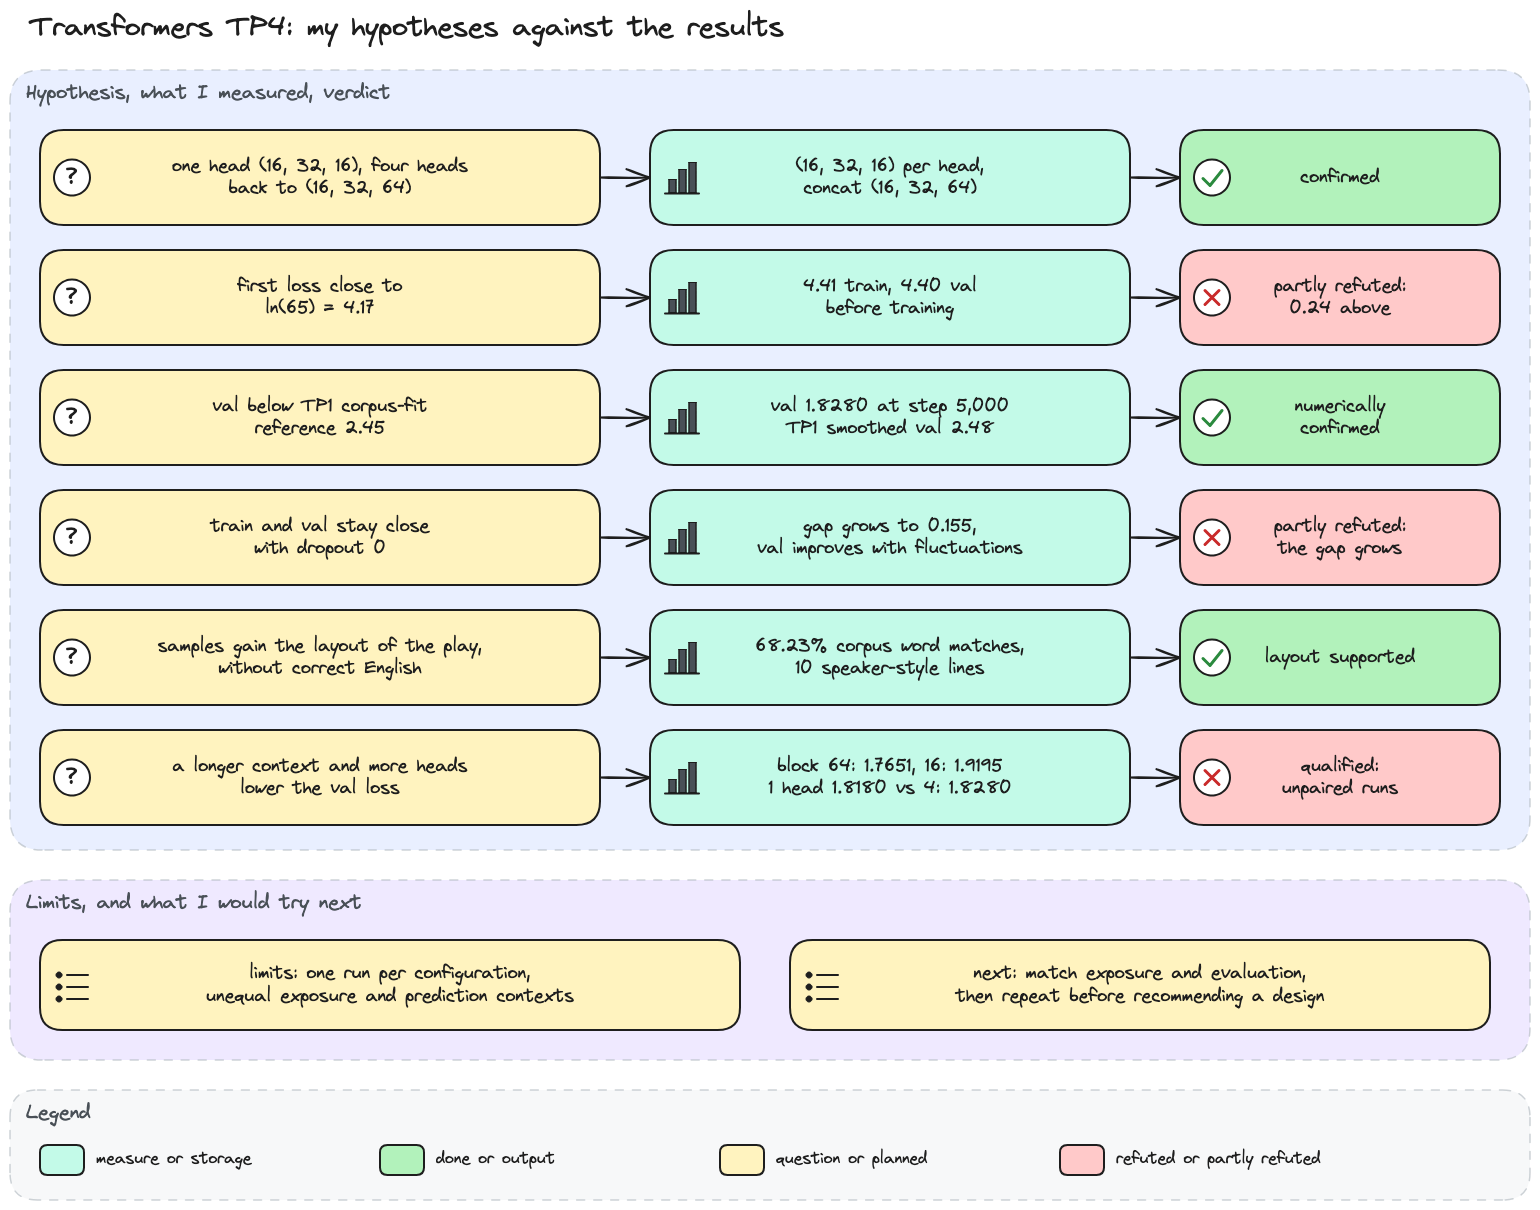

In [76]:
# Summary diagram: my TP4 hypotheses, what I measured, and my verdicts.
display(Image(filename='diagrams/transformers/tp4_summary.png', width=900))

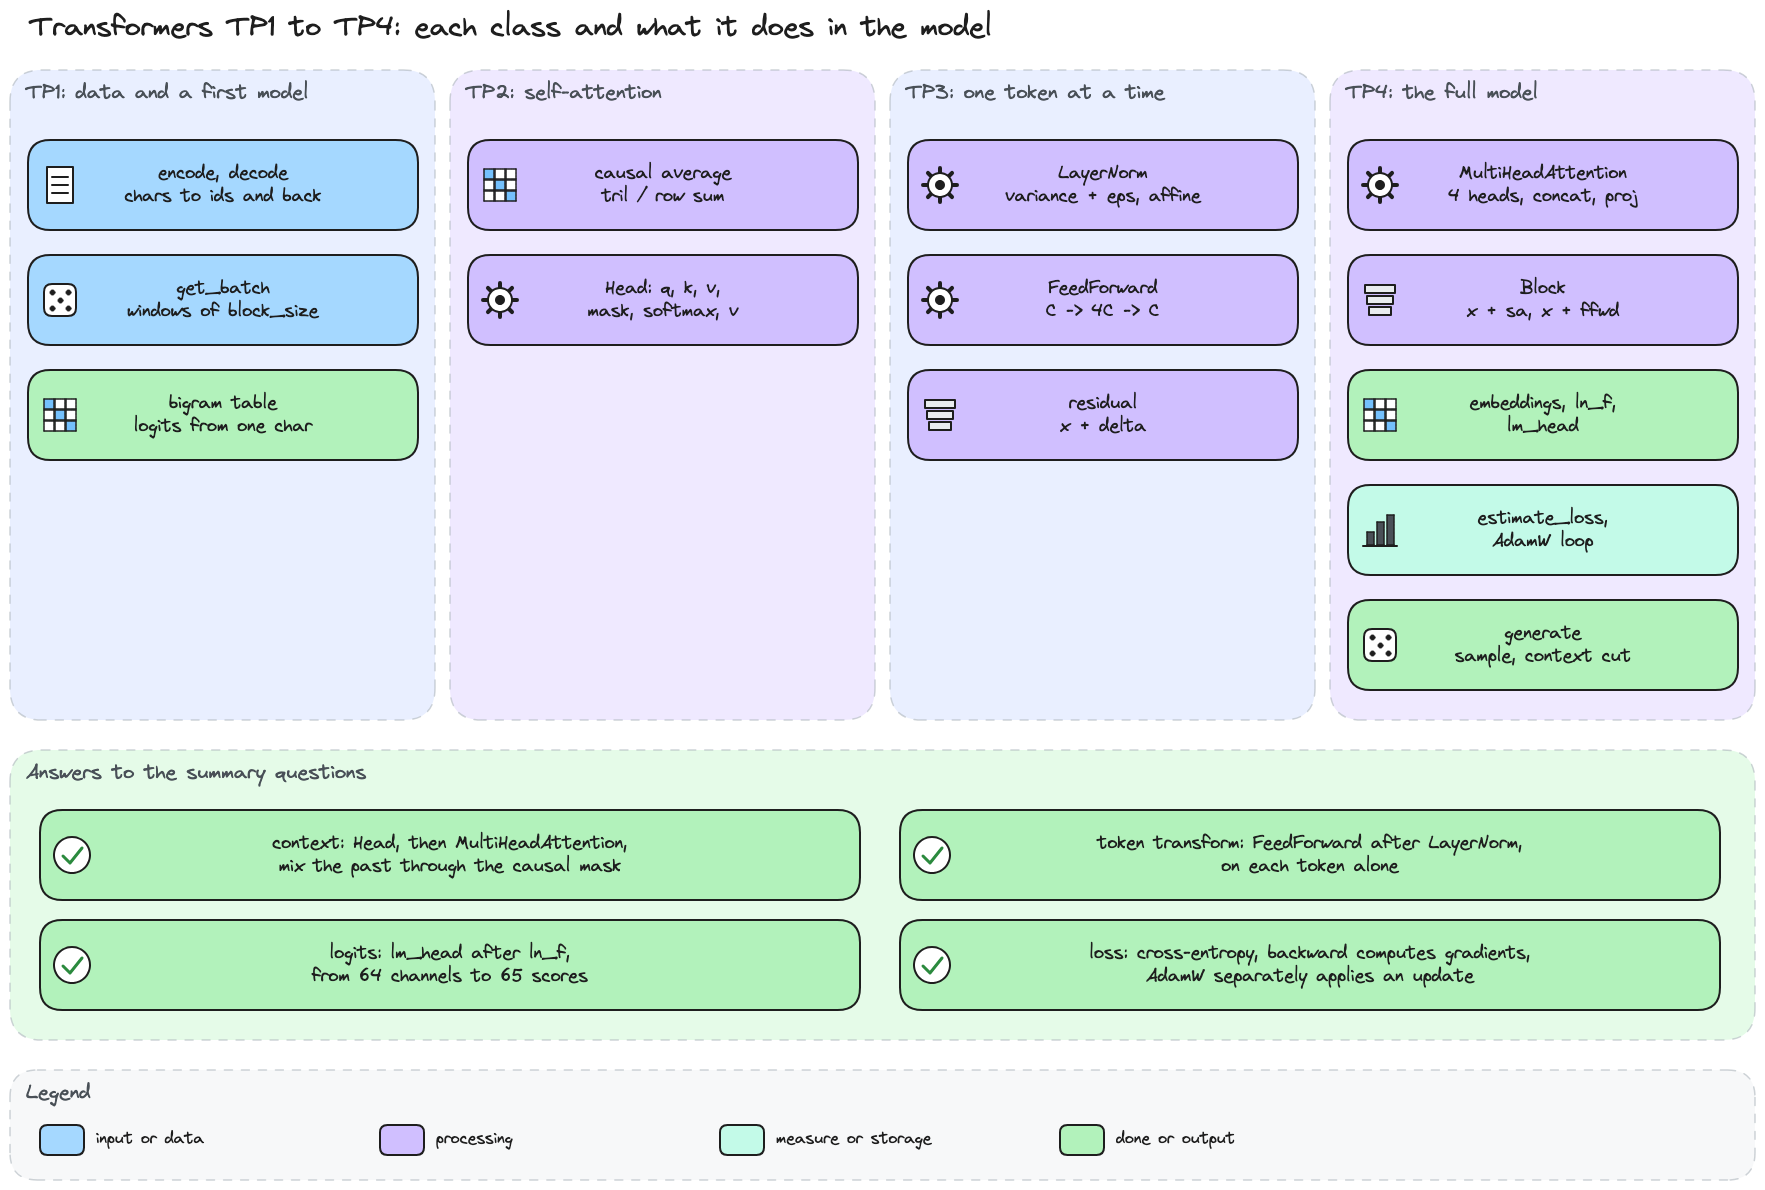

In [77]:
# The classes of the four TPs, what each one does, and my answers to the summary questions.
display(Image(filename='diagrams/transformers/tp4_classes.png', width=900))

uniform guess, ln(65): 4.1744
TP4 model before training, val: 4.4009
TP1 corpus-fitted reference: 2.4500
TP1 smoothed training counts, val: 2.4800
TP4 after 5,000 steps, val: 1.8280
TP4 after 5,000 steps, train: 1.6730
lowest observed run, block_size 64, val: 1.7651


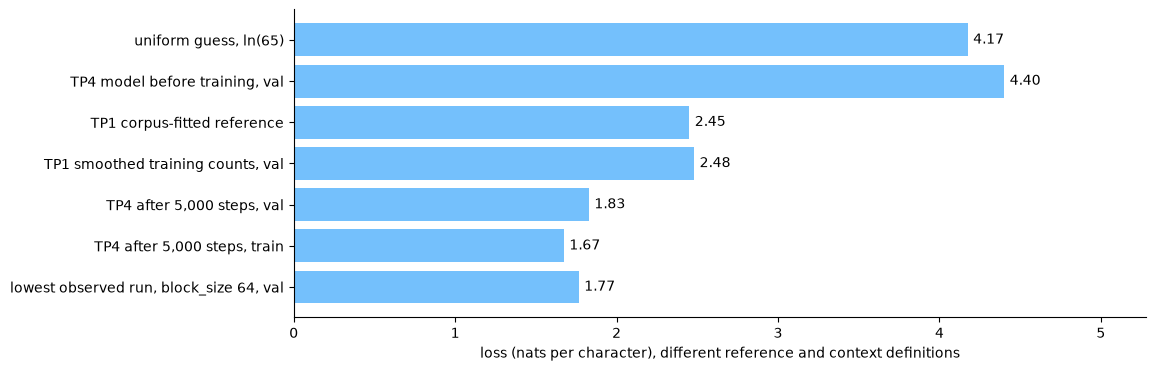

In [78]:
# How far did the four TPs go? The loss levels from a uniform guess to the trained model.
levels = {'uniform guess, ln(65)': math.log(vocab_size),
          'TP4 model before training, val': history['val'][0],
          'TP1 corpus-fitted reference': TP1_FLOOR,
          'TP1 smoothed training counts, val': TP1_VALIDATION_REFERENCE,
          'TP4 after 5,000 steps, val': history['val'][-1],
          'TP4 after 5,000 steps, train': history['train'][-1],
          f'lowest observed run, {best_name}, val': final_val[best_name]}
for name, level in levels.items():
    print(f'{name}: {level:.4f}')

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(list(levels)[::-1], list(levels.values())[::-1], color='#74c0fc')
ax.bar_label(bars, labels=[f'{level:.2f}' for level in list(levels.values())[::-1]], padding=4)
ax.set_xlim(0, max(levels.values()) * 1.2)
ax.set_xlabel('loss (nats per character), different reference and context definitions')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The uniform reference is 4.17 nats, and TP4's baseline goes from about 4.40 to 1.83 on validation. TP1's 2.45 is a reference fitted across the full corpus, while its smoothed model gives 2.48 on validation. These reference definitions matter when judging the apparent gain.

The context-64 run scores about 1.77 under its own prediction-context mixture. TP4 also changes capacity and optimisation from TP1, so the bars cannot assign the improvement to one mechanism.


Loss of the batch: 1.6778
Weights with a non-zero gradient: 208,705 of 209,729
Token embedding rows reached: 49 of 65, distinct characters in the batch: 49


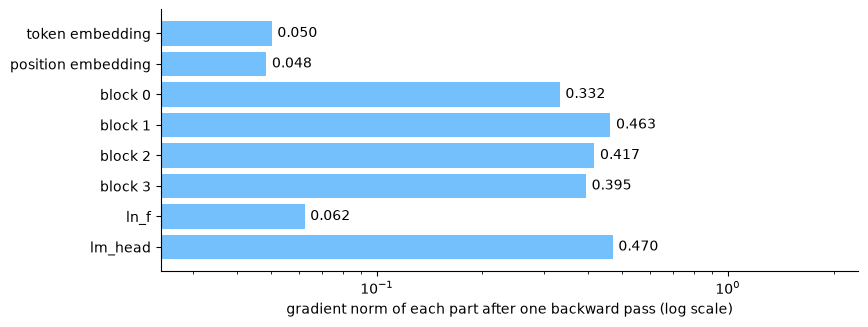

In [79]:
# Where does the loss act? One backward pass of the trained model, part by part.
torch.manual_seed(RANDOM_STATE)
model.zero_grad(set_to_none=True)
xs, ys = get_batch('train')
_, loss = model(xs, ys)
loss.backward()
parts = {'token embedding': model.token_embedding_table,
         'position embedding': model.position_embedding_table,
         **{f'block {i}': block for i, block in enumerate(model.blocks)},
         'ln_f': model.ln_f, 'lm_head': model.lm_head}
norms = {name: math.sqrt(sum(p.grad.pow(2).sum().item() for p in part.parameters()))
         for name, part in parts.items()}
reached = sum((p.grad != 0).sum().item() for p in model.parameters())
total = sum(p.numel() for p in model.parameters())
rows = (model.token_embedding_table.weight.grad.abs().sum(dim=1) > 0).sum().item()
print(f'Loss of the batch: {loss.item():.4f}')
print(f'Weights with a non-zero gradient: {reached:,} of {total:,}')
print(f'Token embedding rows reached: {rows} of {vocab_size}, '
      f'distinct characters in the batch: {len(torch.unique(xs))}')
model.zero_grad(set_to_none=True)

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(list(norms)[::-1], list(norms.values())[::-1], color='#74c0fc')
ax.bar_label(bars, labels=[f'{norm:.3f}' for norm in list(norms.values())[::-1]], padding=4)
ax.set_xscale('log')
ax.set_xlim(min(norms.values()) / 2, max(norms.values()) * 5)
ax.set_xlabel('gradient norm of each part after one backward pass (log scale)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The backward pass gives non-zero gradients to 208,705 of 209,729 parameters. The remaining 1,024 entries belong to the 16 token-embedding rows absent from the batch, while 49 rows are reached.

Each model component receives a gradient, with aggregate norms from 0.048 to 0.470. Those norms depend on parameter count and scale, so they do not rank component importance. This cell applies no optimiser update.

During actual AdamW steps, a zero gradient entry can still move through stored moments or weight decay. The detached-bias example in section 8 explains why a gradient count and an update count answer different questions.


> *My conclusion:*
>
> The assembled model passes the implementation checks and reaches validation loss 1.8280 after 5,000 steps. My hypotheses now have the following scope.
>
> - The expected head and concatenation shapes are confirmed on the tested inputs.
> - Initial losses of 4.41 and 4.40 revise my expectation of uniform predictions. Random logits can be unequal before any learning.
> - Validation falls below the original 2.45 reference and TP1's 2.48 smoothed validation score. This confirms the numerical prediction without isolating context as its cause.
> - The gap reaches 0.155, so my expectation of close curves holds only partly.
> - The sample gains play-like layout and corpus word matches. Its coherent use of language remains unestablished.
> - Longer context has a lower observed score under a different exposure and evaluation mixture. More heads have no demonstrated advantage in the existing unpaired runs.
>
> My answers to the four summary questions:
>
> 1. Head and MultiHeadAttention mix information from the visible prefix through the causal mask.
> 2. FeedForward transforms each token separately after its LayerNorm.
> 3. `lm_head` maps the final normalised representation from 64 channels to 65 logits.
> 4. Cross-entropy is computed at the output, and backward reaches every component. AdamW applies a separate update using gradients, moments and weight decay.
>
> I now check what a reference score measures before comparing it with a curve. I also trace the random draws and prediction contexts before calling a comparison controlled. These habits keep numerical improvements separate from explanations of their cause and from readable generation.
>
> The evidence remains one run per configuration with the existing character model. A later comparison would need matched exposure and evaluation, followed by repeated runs, before I could recommend a design from these small differences.
